# LSTM Autoencoder Analysis Notebook  
## Multiple-stock workflow with SP500, NASDAQ, and VIX

The notebook is based on the current `lstm_autoencoder_detector.py` logic, but it is intentionally scoped to:

- **one or more selected stocks**
- **SP500**
- **NASDAQ**
- **VIX**

This keeps the runtime manageable and makes the analysis easier to interpret.

### Notebook goals

This notebook lets us:

1. select one or more stocks,
2. run the LSTM autoencoder only for that stock and the three indices,
3. inspect anomaly scores, anomaly flags, and event peaks,
4. compare the selected stock against SP500, NASDAQ, and VIX,
5. save stock-specific results if needed.

The notebook is designed so we do **not** run all stocks at once.


## 1. Imports

In [66]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import (
    Input,
    LSTM,
    RepeatVector,
    TimeDistributed,
    Dense,
    Dropout,
    LayerNormalization,
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.max_colwidth", None)

plt.rcParams["figure.figsize"] = (14, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False


### Available stocks in the processed dataset 

AMD
AMZN
GOOGL
HIMS
HOOD
META
MSTR
NVDA
ORCL
PLTR
PLUG
TSLA


### Available indices  
NASDAQ
SP500
VIX


## 2. Configuration

In [73]:
# Change to analyze
# STOCK_SERIES = "AMD"
STOCK_SERIES = ["AMD", "HIMS", "ORCL", "PLUG"]

# INDEX_SERIES = ["SP500", "NASDAQ", "VIX"]
INDEX_SERIES = ["SP500", "VIX"]
# SERIES_TO_RUN = [STOCK_SERIES] + INDEX_SERIES
SERIES_TO_RUN = STOCK_SERIES + INDEX_SERIES

TRAIN_END_DATE = pd.Timestamp("2024-12-31")
SEQUENCE_LENGTH = 15

RANDOM_STATE = 42
EPOCHS = 60
BATCH_SIZE = 32
LEARNING_RATE = 1e-3

FEATURES = [
    "simple_return",
    "abs_simple_return",
    "return_5d",
    "return_10d",
    "gap_pct",
    "hl_range_pct",
    "body_to_range",
    "dist_ma_20",
    "simple_vol_20",
    "vol_ratio_5_20",
    "z_simple_return_20",
    "relative_volume_20",
    "volume_z_20",
    "SP500_simple_return",
    "NASDAQ_simple_return",
    "VIX_simple_return",
    "VIX_z_simple_20",
    "excess_simple_return_sp500",
    "excess_simple_return_nasdaq",
]

Z_SIMPLE_MAX = 1.5
VOLUME_Z_MAX = 2.0
VIX_Z_MAX = 1.5

THRESHOLD_MULTIPLIER = 4.5
TRAIN_THRESHOLD_QUANTILE = 0.995

EVENT_GAP_BARS = 3
PLOT_RAW_ANOMALIES = True

np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

SERIES_TO_RUN


['AMD', 'HIMS', 'ORCL', 'PLUG', 'SP500', 'VIX']

## 3. File paths

In [74]:
# INPUT_PATH = Path("data/processed/market_data_features_2021_2026.csv")
# OUTPUT_DIR = Path("results/notebooks/lstm_single_stock")
# OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# RESULTS_PATH = OUTPUT_DIR / f"lstm_results_SINGLE_STOCK.csv" #f"lstm_results_{STOCK_SERIES}.csv"
# SUMMARY_PATH = OUTPUT_DIR / f"lstm_summary_SINGLE_STOCK.csv" #f"lstm_summary_{STOCK_SERIES}.csv"
PROJECT_ROOT = Path(r"G:\My Drive\MSc. in Data Science\S4 Project in Data Science\project")

INPUT_PATH = PROJECT_ROOT / "data" / "processed" / "market_data_features_2021_2026.csv"
OUTPUT_DIR = PROJECT_ROOT / "results" / "notebooks" / "lstm_single_stock"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RESULTS_PATH = OUTPUT_DIR / "lstm_results_SINGLE_STOCK.csv"
SUMMARY_PATH = OUTPUT_DIR / "lstm_summary_SINGLE_STOCK.csv"

assert INPUT_PATH.exists(), f"Missing file: {INPUT_PATH}"

INPUT_PATH, RESULTS_PATH, SUMMARY_PATH


(WindowsPath('G:/My Drive/MSc. in Data Science/S4 Project in Data Science/project/data/processed/market_data_features_2021_2026.csv'),
 WindowsPath('G:/My Drive/MSc. in Data Science/S4 Project in Data Science/project/results/notebooks/lstm_single_stock/lstm_results_SINGLE_STOCK.csv'),
 WindowsPath('G:/My Drive/MSc. in Data Science/S4 Project in Data Science/project/results/notebooks/lstm_single_stock/lstm_summary_SINGLE_STOCK.csv'))

## 4. Load features dataset

In [75]:
df = pd.read_csv(INPUT_PATH, parse_dates=["Date"], low_memory=False)
df = df.sort_values(["SeriesName", "Date"]).reset_index(drop=True)

print("Dataset shape:", df.shape)
print("Unique series:", df["SeriesName"].nunique())
display(df.head())


Dataset shape: (19770, 74)
Unique series: 15


,Date,SeriesName,Ticker,AssetType,Sector,Industry,Exchange,Currency,Open,High,Low,Close,Adj Close,Volume,Price,simple_return,abs_simple_return,log_return,abs_log_return,return_5d,return_10d,return_20d,z_simple_return_20,z_return_20,hl_range_pct,oc_change_pct,gap_pct,body_to_range,upper_shadow_pct,lower_shadow_pct,range_expansion_20,ma_5,ma_20,ma_60,dist_ma_20,dist_ma_60,ma_spread_5_20,vol_5,vol_20,vol_60,simple_vol_5,simple_vol_20,simple_vol_60,vol_ratio_5_20,log_volume,volume_change,volume_z_20,relative_volume_20,dollar_volume,SP500_level,SP500_simple_return,SP500_log_return,SP500_simple_vol_20,SP500_vol_20,SP500_z_simple_20,SP500_z_20,NASDAQ_level,NASDAQ_simple_return,NASDAQ_log_return,NASDAQ_simple_vol_20,NASDAQ_vol_20,NASDAQ_z_simple_20,NASDAQ_z_20,VIX_level,VIX_simple_return,VIX_log_return,VIX_simple_vol_20,VIX_vol_20,VIX_z_simple_20,VIX_z_20,excess_return_sp500,excess_return_nasdaq,excess_simple_return_sp500,excess_simple_return_nasdaq
0,2021-01-04,AMD,AMD,EQUITY,Technology,Semiconductors,NMS,USD,92.110001,96.059998,90.919998,92.300003,92.300003,51802600.0,92.300003,0.006433,0.006433,0.006413,0.006413,0.005337,-0.046881,-0.000108,0.378940,0.386154,0.055688,0.002063,0.004362,0.036965,0.040737,0.012893,1.787670,91.704001,93.197501,86.520000,-0.009630,0.066805,-0.016025,0.010292,0.016621,0.023782,0.010334,0.016627,0.023836,0.621507,17.762951,1.077864,1.203970,1.384963,4.781380e+09,3700.649902,-0.014755,-0.014865,0.006167,0.006168,-2.470315,-2.484491,12698.450195,-0.014729,-0.014838,0.007350,0.007378,-2.182098,-2.184968,26.969999,0.185494,0.170160,0.067333,0.064233,2.546176,2.464659,0.021278,0.021251,0.021188,0.021162
1,2021-01-05,AMD,AMD,EQUITY,Technology,Semiconductors,NMS,USD,92.099998,93.209999,91.410004,92.769997,92.769997,34208000.0,92.769997,0.005092,0.005092,0.005079,0.005079,0.012773,-0.032840,-0.013505,0.349949,0.357266,0.019403,0.007275,-0.002167,0.372222,0.004743,0.007438,0.646304,91.938000,93.134000,86.624333,-0.003908,0.070946,-0.012842,0.010233,0.016120,0.023784,0.010269,0.016122,0.023837,0.636956,17.347970,-0.339647,-0.097812,0.928670,3.173476e+09,3726.860107,0.007083,0.007058,0.006059,0.006062,1.104221,1.102702,12818.959961,0.009490,0.009445,0.007464,0.007490,1.079560,1.073676,25.340000,-0.060437,-0.062341,0.068840,0.065844,-1.054928,-1.097078,-0.001979,-0.004366,-0.001991,-0.004398
2,2021-01-06,AMD,AMD,EQUITY,Technology,Semiconductors,NMS,USD,91.620003,92.279999,89.459999,90.330002,90.330002,51911700.0,90.330002,-0.026302,0.026302,-0.026654,0.026654,-0.003200,-0.031106,-0.039758,-1.430945,-1.441814,0.031219,-0.014080,-0.012396,0.457447,0.007306,0.009631,1.023466,91.880000,92.947001,86.744833,-0.028156,0.041330,-0.011480,0.015156,0.017079,0.023452,0.015079,0.017066,0.023519,0.883532,17.765055,0.517531,1.192347,1.386520,4.689184e+09,3748.139893,0.005710,0.005694,0.006141,0.006144,0.803731,0.803833,12740.790039,-0.006098,-0.006117,0.007603,0.007628,-0.920890,-0.916483,25.070000,-0.010655,-0.010712,0.068951,0.065904,-0.305710,-0.286180,-0.032347,-0.020537,-0.032011,-0.020204
3,2021-01-07,AMD,AMD,EQUITY,Technology,Semiconductors,NMS,USD,91.330002,95.510002,91.199997,95.160004,95.160004,42897200.0,95.160004,0.053471,0.053471,0.052090,0.052090,0.031098,0.021468,0.024107,2.515840,2.476254,0.045292,0.041936,0.011071,0.888630,0.003678,0.001366,1.449838,92.454001,93.059001,86.926000,0.022577,0.094724,-0.006501,0.025857,0.020555,0.024283,0.026259,0.020696,0.024388,1.268814,17.574317,-0.173651,0.543188,1.132158,4.082098e+09,3803.790039,0.014847,0.014738,0.006859,0.006853,1.963853,1.953328,13067.480469,0.025641,0.025318,0.009300,0.009283,2.548990,2.523734,22.370001,-0.107698,-0.113951,0.073200,0.070710,-1.560001,-1.667062,0.037352,0.026772,0.038623,0.027829
4,2021-01-08,AMD,AMD,EQUITY,Technology,Semiconductors,NMS,USD,95.980003,96.400002,93.269997,94.580002,94.580002,39816400.0,94.580002,-0.006095,0.006095,-0.006114,0.006114,0.031294,0.033097,0.052878,-0.460945,-0.456761,0.033094,-0.014586,0.008617,0.447284,0.004441,0.01

## 5. Restrict to one stock + indices

In [76]:
subset_df = df[df["SeriesName"].isin(SERIES_TO_RUN)].copy()
subset_df = subset_df.sort_values(["SeriesName", "Date"]).reset_index(drop=True)

print("Subset shape:", subset_df.shape)
print("Series in subset:", subset_df["SeriesName"].unique().tolist())

display(
    subset_df.groupby("SeriesName", as_index=False)
    .agg(
        start_date=("Date", "min"),
        end_date=("Date", "max"),
        n_rows=("Date", "count"),
    )
)


Subset shape: (7908, 74)
Series in subset: ['AMD', 'HIMS', 'ORCL', 'PLUG', 'SP500', 'VIX']


,SeriesName,start_date,end_date,n_rows
0,AMD,2021-01-04,2026-04-02,1318
1,HIMS,2021-01-04,2026-04-02,1318
2,ORCL,2021-01-04,2026-04-02,1318
3,PLUG,2021-01-04,2026-04-02,1318
4,SP500,2021-01-04,2026-04-02,1318
5,VIX,2021-01-04,2026-04-02,1318


## 6. Quick sanity check

In [77]:
required_view = ["Date", "SeriesName", "Price"] + FEATURES
available = [c for c in required_view if c in subset_df.columns]
missing = [c for c in required_view if c not in subset_df.columns]

print("Missing columns:", missing)
display(subset_df[available].head())


Missing columns: []


,Date,SeriesName,Price,simple_return,abs_simple_return,return_5d,return_10d,gap_pct,hl_range_pct,body_to_range,dist_ma_20,simple_vol_20,vol_ratio_5_20,z_simple_return_20,relative_volume_20,volume_z_20,SP500_simple_return,NASDAQ_simple_return,VIX_simple_return,VIX_z_simple_20,excess_simple_return_sp500,excess_simple_return_nasdaq
0,2021-01-04,AMD,92.300003,0.006433,0.006433,0.005337,-0.046881,0.004362,0.055688,0.036965,-0.009630,0.016627,0.621507,0.378940,1.384963,1.203970,-0.014755,-0.014729,0.185494,2.546176,0.021188,0.021162
1,2021-01-05,AMD,92.769997,0.005092,0.005092,0.012773,-0.032840,-0.002167,0.019403,0.372222,-0.003908,0.016122,0.636956,0.349949,0.928670,-0.097812,0.007083,0.009490,-0.060437,-1.054928,-0.001991,-0.004398
2,2021-01-06,AMD,90.330002,-0.026302,0.026302,-0.003200,-0.031106,-0.012396,0.031219,0.457447,-0.028156,0.017066,0.883532,-1.430945,1.386520,1.192347,0.005710,-0.006098,-0.010655,-0.305710,-0.032011,-0.020204
3,2021-01-07,AMD,95.160004,0.053471,0.053471,0.031098,0.021468,0.011071,0.045292,0.888630,0.022577,0.020696,1.268814,2.515840,1.132158,0.543188,0.014847,0.025641,-0.107698,-1.560001,0.038623,0.027829
4,2021-01-08,AMD,94.580002,-0.006095,0.006095,0.031294,0.033097,0.008617,0.033094,0.447284,0.013757,0.019215,1.365630,-0.460945,1.068264,0.362030,0.005492,0.010293,-0.036209,-0.515276,-0.011587,-0.016388


## 7. Helper functions from the detector

In [78]:
def robust_scale_train_full(train_df: pd.DataFrame, full_df: pd.DataFrame):
    medians = train_df.median()
    q1 = train_df.quantile(0.25)
    q3 = train_df.quantile(0.75)
    iqr = (q3 - q1).replace(0, 1.0)
    train_scaled = (train_df - medians) / iqr
    full_scaled = (full_df - medians) / iqr
    return train_scaled, full_scaled


def make_sequences(X: np.ndarray, seq_len: int) -> np.ndarray:
    sequences = []
    for i in range(seq_len - 1, len(X)):
        sequences.append(X[i - seq_len + 1 : i + 1])
    return np.array(sequences)


def last_step_mse(x_true: np.ndarray, x_pred: np.ndarray) -> np.ndarray:
    return np.mean((x_true[:, -1, :] - x_pred[:, -1, :]) ** 2, axis=1)


def robust_threshold(train_errors: np.ndarray, multiplier: float = THRESHOLD_MULTIPLIER) -> float:
    train_errors = np.asarray(train_errors)
    train_errors = train_errors[~np.isnan(train_errors)]
    median = np.median(train_errors)
    mad = np.median(np.abs(train_errors - median))
    robust_sigma = 1.4826 * mad
    if robust_sigma == 0:
        robust_sigma = np.std(train_errors) if np.std(train_errors) > 0 else 1e-6
    return median + multiplier * robust_sigma


def combined_threshold(train_errors: np.ndarray) -> float:
    mad_thr = robust_threshold(train_errors, THRESHOLD_MULTIPLIER)
    q_thr = np.quantile(train_errors, TRAIN_THRESHOLD_QUANTILE)
    return 0.5 * mad_thr + 0.5 * q_thr


def build_lstm_autoencoder(seq_len: int, n_features: int) -> Model:
    inputs = Input(shape=(seq_len, n_features))
    x = LSTM(48, return_sequences=True, activation="tanh")(inputs)
    x = Dropout(0.2)(x)
    x = LSTM(24, activation="tanh")(x)
    x = LayerNormalization()(x)
    x = RepeatVector(seq_len)(x)
    x = LSTM(24, return_sequences=True, activation="tanh")(x)
    x = Dropout(0.2)(x)
    x = LSTM(48, return_sequences=True, activation="tanh")(x)
    outputs = TimeDistributed(Dense(n_features))(x)
    model = Model(inputs, outputs)
    model.compile(optimizer=Adam(learning_rate=LEARNING_RATE), loss=tf.keras.losses.Huber())
    return model


## 8. Data-preparation and scoring helpers

In [79]:
def prepare_group_data(group: pd.DataFrame):
    group = group.sort_values("Date").copy()
    available_features = [c for c in FEATURES if c in group.columns]
    if not available_features:
        raise ValueError("No requested features are available.")

    train_mask = group["Date"] <= TRAIN_END_DATE
    train_df = group.loc[train_mask].copy()
    if train_df.empty:
        raise ValueError("Training split is empty.")

    X_train = train_df[available_features].replace([np.inf, -np.inf], np.nan).copy()
    X_full = group[available_features].replace([np.inf, -np.inf], np.nan).copy()

    train_medians = X_train.median(numeric_only=True)
    X_train = X_train.fillna(train_medians)
    X_full = X_full.fillna(train_medians)

    valid_cols = [c for c in available_features if X_train[c].notna().any() and X_full[c].notna().any()]
    X_train = X_train[valid_cols]
    X_full = X_full[valid_cols]

    if X_train.shape[1] == 0:
        raise ValueError("No valid features remain after NaN handling.")

    X_train_scaled, X_full_scaled = robust_scale_train_full(X_train, X_full)
    return train_df, group, valid_cols, X_train_scaled, X_full_scaled


def build_clean_training_mask(train_df: pd.DataFrame) -> np.ndarray:
    n = len(train_df)
    keep = []

    z_col = "z_simple_return_20" if "z_simple_return_20" in train_df.columns else None
    vol_col = "volume_z_20" if "volume_z_20" in train_df.columns else None
    vix_col = "VIX_z_simple_20" if "VIX_z_simple_20" in train_df.columns else None

    for end_idx in range(SEQUENCE_LENGTH - 1, n):
        window = train_df.iloc[end_idx - SEQUENCE_LENGTH + 1 : end_idx + 1]
        ok = True

        if z_col is not None:
            vals = window[z_col].to_numpy(dtype=float)
            vals = vals[~np.isnan(vals)]
            if len(vals) == 0:
                ok = False
            elif np.max(np.abs(vals)) > Z_SIMPLE_MAX:
                ok = False

        if vol_col is not None:
            vals = window[vol_col].to_numpy(dtype=float)
            vals = vals[~np.isnan(vals)]
            if len(vals) == 0:
                ok = False
            elif np.max(np.abs(vals)) > VOLUME_Z_MAX:
                ok = False

        if vix_col is not None:
            vals = window[vix_col].to_numpy(dtype=float)
            vals = vals[~np.isnan(vals)]
            if len(vals) == 0:
                ok = False
            elif np.max(np.abs(vals)) > VIX_Z_MAX:
                ok = False

        keep.append(ok)

    return np.array(keep, dtype=bool)


def add_event_peaks_from_flag(full_group: pd.DataFrame, flag_col: str, peak_col: str, group_col: str, gap_bars: int = EVENT_GAP_BARS) -> pd.DataFrame:
    full_group = full_group.copy()
    full_group[group_col] = np.nan
    full_group[peak_col] = False

    anomaly_idx = full_group.index[full_group[flag_col].fillna(False)].to_list()
    if not anomaly_idx:
        return full_group

    group_ids = []
    current_group = 0
    prev_idx = anomaly_idx[0]

    for i, idx in enumerate(anomaly_idx):
        if i == 0:
            group_ids.append(current_group)
            continue

        if (idx - prev_idx) <= gap_bars:
            group_ids.append(current_group)
        else:
            current_group += 1
            group_ids.append(current_group)

        prev_idx = idx

    full_group.loc[anomaly_idx, group_col] = group_ids

    event_peak_idx = (
        full_group.loc[anomaly_idx]
        .groupby(group_col)["lstm_score"]
        .idxmax()
    )
    full_group.loc[event_peak_idx, peak_col] = True
    return full_group


def score_group(group: pd.DataFrame) -> pd.DataFrame:
    train_df, full_group, used_features, X_train_scaled, X_full_scaled = prepare_group_data(group)

    X_train_seq = make_sequences(X_train_scaled.values, SEQUENCE_LENGTH)
    X_full_seq = make_sequences(X_full_scaled.values, SEQUENCE_LENGTH)

    if len(X_train_seq) == 0 or len(X_full_seq) == 0:
        raise ValueError("Not enough observations to build sequences.")

    clean_mask = build_clean_training_mask(train_df)
    if clean_mask.sum() >= max(20, int(0.2 * len(clean_mask))):
        X_train_seq_clean = X_train_seq[clean_mask]
    else:
        X_train_seq_clean = X_train_seq

    model = build_lstm_autoencoder(SEQUENCE_LENGTH, X_train_seq_clean.shape[2])

    validation_split = 0.1 if len(X_train_seq_clean) >= 30 else 0.0
    monitor_metric = "val_loss" if validation_split > 0 else "loss"

    callbacks = [
        EarlyStopping(monitor=monitor_metric, patience=8, restore_best_weights=True),
        ReduceLROnPlateau(monitor=monitor_metric, factor=0.5, patience=3, verbose=0),
    ]

    model.fit(
        X_train_seq_clean,
        X_train_seq_clean,
        validation_split=validation_split,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        verbose=0,
        callbacks=callbacks
    )

    recon_full = model.predict(X_full_seq, verbose=0)
    full_errors = last_step_mse(X_full_seq, recon_full)

    recon_train = model.predict(X_train_seq_clean, verbose=0)
    train_errors = last_step_mse(X_train_seq_clean, recon_train)

    threshold = combined_threshold(train_errors)

    full_group = full_group.copy()
    full_group["lstm_score"] = np.nan
    full_group.iloc[SEQUENCE_LENGTH - 1 :, full_group.columns.get_loc("lstm_score")] = full_errors

    full_group["lstm_threshold"] = threshold
    full_group["lstm_is_anomaly_all"] = full_group["lstm_score"] >= threshold

    full_group["lstm_is_anomaly"] = False
    post_train_mask = full_group["Date"] > TRAIN_END_DATE
    full_group.loc[post_train_mask, "lstm_is_anomaly"] = (
        full_group.loc[post_train_mask, "lstm_score"] >= threshold
    )

    full_group = add_event_peaks_from_flag(full_group, "lstm_is_anomaly_all", "lstm_is_event_peak_all", "lstm_event_group_all")
    full_group = add_event_peaks_from_flag(full_group, "lstm_is_anomaly", "lstm_is_event_peak", "lstm_event_group")

    full_group["lstm_used_n_features"] = len(used_features)
    full_group["lstm_features_used"] = ", ".join(used_features)
    full_group["lstm_train_end_date"] = TRAIN_END_DATE
    full_group["lstm_sequence_length"] = SEQUENCE_LENGTH
    full_group["lstm_clean_train_sequences"] = len(X_train_seq_clean)
    full_group["lstm_all_train_sequences"] = len(X_train_seq)

    return full_group


## 9. Run the detector only for the selected stock and the three indices

In [80]:
results_parts = []

for series_name, group in subset_df.groupby("SeriesName", sort=False):
    try:
        out = score_group(group)
        results_parts.append(out)
        print(f"Finished: {series_name}")
    except Exception as e:

        print(f"Skipped {series_name}: {e}")

results_df = pd.concat(results_parts, ignore_index=True)
print("Results shape:", results_df.shape)
# display(results_df.head())


Finished: AMD
Finished: HIMS
Finished: ORCL
Finished: PLUG
Finished: SP500
Finished: VIX
Results shape: (7908, 88)


In [81]:
# results_df.head(1)

# results_df['lstm_is_anomaly'].unique()
# results_df['lstm_is_anomaly'] == 'True'
# results_df[results_df['lstm_is_anomaly'] == 'True']['Date']

# results_df[results_df['lstm_is_anomaly'] == True][['Ticker', 'Date']]

cond = (results_df["lstm_is_anomaly"] == True) & (results_df["SeriesName"] == "AMD")
results_df.loc[cond, ["Ticker", "Date", "lstm_is_anomaly", "lstm_is_event_peak"]]




,Ticker,Date,lstm_is_anomaly,lstm_is_event_peak
1027,AMD,2025-02-05,True,True
1067,AMD,2025-04-03,True,False
1068,AMD,2025-04-04,True,False
1071,AMD,2025-04-09,True,True
1072,AMD,2025-04-10,True,False
1076,AMD,2025-04-16,True,True
1117,AMD,2025-06-16,True,True
1194,AMD,2025-10-06,True,True
1198,AMD,2025-10-10,True,True
1201,AMD,2025-10-15,True,False


In [82]:
cond = (results_df["lstm_is_anomaly"] == True) & (results_df["SeriesName"] == "AMD")
results_df.loc[cond, ["Ticker", "Date", "lstm_is_anomaly", "lstm_is_event_peak"]]

,Ticker,Date,lstm_is_anomaly,lstm_is_event_peak
1027,AMD,2025-02-05,True,True
1067,AMD,2025-04-03,True,False
1068,AMD,2025-04-04,True,False
1071,AMD,2025-04-09,True,True
1072,AMD,2025-04-10,True,False
1076,AMD,2025-04-16,True,True
1117,AMD,2025-06-16,True,True
1194,AMD,2025-10-06,True,True
1198,AMD,2025-10-10,True,True
1201,AMD,2025-10-15,True,False


In [83]:
cond = (results_df["lstm_is_anomaly"] == True) & (results_df["SeriesName"] == "VIX")
results_df.loc[cond, ["Ticker", "Date", "lstm_is_anomaly", "lstm_is_event_peak"]]

,Ticker,Date,lstm_is_anomaly,lstm_is_event_peak
7610,^VIX,2025-01-27,True,True
7615,^VIX,2025-02-03,True,True
7657,^VIX,2025-04-03,True,False
7658,^VIX,2025-04-04,True,False
7659,^VIX,2025-04-07,True,False
7660,^VIX,2025-04-08,True,False
7661,^VIX,2025-04-09,True,True
7662,^VIX,2025-04-10,True,False
7788,^VIX,2025-10-10,True,True
7856,^VIX,2026-01-20,True,True


## 10. Summary table

In [85]:
summary_df = (
    results_df.groupby(["SeriesName", "Ticker"], as_index=False)
    .agg(
        n_rows=("Date", "count"),
        n_anomalies_all=("lstm_is_anomaly_all", "sum"),
        n_event_peaks_all=("lstm_is_event_peak_all", "sum"),
        n_anomalies_detected=("lstm_is_anomaly", "sum"),
        n_event_peaks_detected=("lstm_is_event_peak", "sum"),
        anomaly_rate_detected=("lstm_is_anomaly", "mean"),
        event_peak_rate_detected=("lstm_is_event_peak", "mean"),
        avg_score=("lstm_score", "mean"),
        max_score=("lstm_score", "max"),
        threshold=("lstm_threshold", "max"),
        n_features=("lstm_used_n_features", "max"),
        clean_train_sequences=("lstm_clean_train_sequences", "max"),
        all_train_sequences=("lstm_all_train_sequences", "max"),
    )
    .sort_values(["SeriesName", "Ticker"])
    .reset_index(drop=True)
)

display(summary_df)


,SeriesName,Ticker,n_rows,n_anomalies_all,n_event_peaks_all,n_anomalies_detected,n_event_peaks_detected,anomaly_rate_detected,event_peak_rate_detected,avg_score,max_score,threshold,n_features,clean_train_sequences,all_train_sequences
0,AMD,AMD,1318,25,21,13,9,0.009863,0.006829,0.560961,40.458090,2.720391,19,991,991
1,HIMS,HIMS,1318,23,19,11,8,0.008346,0.006070,0.818515,51.924776,5.087439,19,991,991
2,ORCL,ORCL,1318,15,14,7,6,0.005311,0.004552,1.224528,223.144769,11.643545,19,991,991
3,PLUG,PLUG,1318,26,20,13,8,0.009863,0.006070,0.696329,44.441321,3.976663,19,991,991
4,SP500,^GSPC,1318,32,26,13,7,0.009863,0.005311,0.502663,23.708354,2.434504,17,991,991
5,VIX,^VIX,1318,21,13,10,5,0.007587,0.003794,0.649314,29.466934,4.403487,15,991,991


## 11. Save results (if requested)

In [108]:
results_df.to_csv(RESULTS_PATH, index=False)
summary_df.to_csv(SUMMARY_PATH, index=False)

print(f"Saved detailed results to: {RESULTS_PATH}")
print(f"Saved summary table to: {SUMMARY_PATH}")


Saved detailed results to: G:\My Drive\MSc. in Data Science\S4 Project in Data Science\project\results\notebooks\lstm_single_stock\lstm_results_SINGLE_STOCK.csv
Saved summary table to: G:\My Drive\MSc. in Data Science\S4 Project in Data Science\project\results\notebooks\lstm_single_stock\lstm_summary_SINGLE_STOCK.csv


## 12. Plotting helpers

In [87]:
# def plot_anomalies(series_name: str, df_in: pd.DataFrame, volume_style: str = "bars"):
#     group = df_in[df_in["SeriesName"] == series_name].sort_values("Date").copy()

#     train_anomalies = group[
#         (group["lstm_is_anomaly_all"]) & (group["Date"] <= TRAIN_END_DATE)
#     ].copy()
#     post_anomalies = group[group["lstm_is_anomaly"]].copy()

#     train_peaks = group[
#         (group["lstm_is_event_peak_all"]) & (group["Date"] <= TRAIN_END_DATE)
#     ].copy()
#     post_peaks = group[group["lstm_is_event_peak"]].copy()

#     has_volume = "Volume" in group.columns and group["Volume"].notna().any()

#     volume_style = volume_style.lower()
#     if volume_style not in {"bars", "line"}:
#         raise ValueError("volume_style must be either 'bars' or 'line'.")

#     if has_volume:
#         fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)
#         ax_price, ax_vol = axes
#     else:
#         fig, ax_price = plt.subplots(1, 1, figsize=(14, 5))
#         ax_vol = None

#     # -------------------------
#     # 1. PRICE CHART
#     # -------------------------
#     ax_price.plot(group["Date"], group["Price"], label="Price", linewidth=1.5, color="blue")

#     ax_price.axvspan(
#         group["Date"].min(),
#         TRAIN_END_DATE,
#         color="lightgrey",
#         alpha=0.15,
#         label="Training period"
#     )

#     ax_price.axvline(
#         x=TRAIN_END_DATE,
#         color="green",
#         linestyle="-",
#         linewidth=2.0,
#         alpha=0.9,
#         label="Train end"
#     )

#     all_anomaly_dates = pd.concat(
#         [train_anomalies["Date"], post_anomalies["Date"]]
#     ).sort_values()

#     for anomaly_date in all_anomaly_dates:
#         ax_price.axvline(
#             x=anomaly_date,
#             color="grey",
#             linestyle="--",
#             linewidth=0.8,
#             alpha=0.45,
#             zorder=1
#         )

#     if not train_anomalies.empty:
#         ax_price.scatter(
#             train_anomalies["Date"],
#             train_anomalies["Price"],
#             color="red",
#             s=18,
#             alpha=0.35,
#             label="Train anomaly",
#             zorder=3
#         )

#     if not post_anomalies.empty:
#         ax_price.scatter(
#             post_anomalies["Date"],
#             post_anomalies["Price"],
#             color="red",
#             s=32,
#             alpha=0.95,
#             label="Post-train anomaly",
#             zorder=4
#         )

#     if not train_peaks.empty:
#         ax_price.scatter(
#             train_peaks["Date"],
#             train_peaks["Price"],
#             color="yellow",
#             edgecolor="black",
#             marker="^",
#             s=70,
#             alpha=0.55,
#             label="Train event peak",
#             zorder=5
#         )

#     if not post_peaks.empty:
#         ax_price.scatter(
#             post_peaks["Date"],
#             post_peaks["Price"],
#             color="yellow",
#             edgecolor="black",
#             marker="^",
#             s=110,
#             alpha=1.0,
#             label="Post-train event peak",
#             zorder=6
#         )

#     ax_price.set_title(f"{series_name} - Price with LSTM anomalies", pad=20)
#     ax_price.set_ylabel("Price")
#     ax_price.legend()

#     # -------------------------
#     # 2. VOLUME CHART
#     # -------------------------
#     if has_volume:
#         if volume_style == "bars":
#             ax_vol.bar(
#                 group["Date"],
#                 group["Volume"],
#                 color="gold",
#                 alpha=0.75,
#                 width=1.0,
#                 label="Volume"
#             )
#         elif volume_style == "line":
#             ax_vol.plot(
#                 group["Date"],
#                 group["Volume"],
#                 color="gold",
#                 linewidth=1.3,
#                 label="Volume"
#             )

#         ax_vol.axvspan(
#             group["Date"].min(),
#             TRAIN_END_DATE,
#             color="lightgrey",
#             alpha=0.15,
#             label="Training period"
#         )

#         ax_vol.axvline(
#             x=TRAIN_END_DATE,
#             color="green",
#             linestyle="-",
#             linewidth=2.0,
#             alpha=0.9,
#             label="Train end"
#         )

#         for anomaly_date in all_anomaly_dates:
#             ax_vol.axvline(
#                 x=anomaly_date,
#                 color="grey",
#                 linestyle="--",
#                 linewidth=0.8,
#                 alpha=0.45,
#                 zorder=1
#             )

#         if not train_anomalies.empty:
#             ax_vol.scatter(
#                 train_anomalies["Date"],
#                 train_anomalies["Volume"],
#                 color="red",
#                 s=18,
#                 alpha=0.35,
#                 label="Train anomaly",
#                 zorder=3
#             )

#         if not post_anomalies.empty:
#             ax_vol.scatter(
#                 post_anomalies["Date"],
#                 post_anomalies["Volume"],
#                 color="red",
#                 s=32,
#                 alpha=0.95,
#                 label="Post-train anomaly",
#                 zorder=4
#             )

#         if not train_peaks.empty:
#             ax_vol.scatter(
#                 train_peaks["Date"],
#                 train_peaks["Volume"],
#                 color="yellow",
#                 edgecolor="black",
#                 marker="^",
#                 s=70,
#                 alpha=0.55,
#                 label="Train event peak",
#                 zorder=5
#             )

#         if not post_peaks.empty:
#             ax_vol.scatter(
#                 post_peaks["Date"],
#                 post_peaks["Volume"],
#                 color="yellow",
#                 edgecolor="black",
#                 marker="^",
#                 s=110,
#                 alpha=1.0,
#                 label="Post-train event peak",
#                 zorder=6
#             )

#         ax_vol.set_title(f"{series_name} - Volume with LSTM anomalies", pad=20)
#         ax_vol.set_xlabel("Date")
#         ax_vol.set_ylabel("Volume")
#         ax_vol.legend()

#     plt.tight_layout()
#     plt.show()
def plot_price_volume_and_anomalies(series_name: str, df_in: pd.DataFrame, volume_style: str = "line"):
    group = df_in[df_in["SeriesName"] == series_name].sort_values("Date").copy()

    train_anomalies = group[
        (group["lstm_is_anomaly_all"]) & (group["Date"] <= TRAIN_END_DATE)
    ].copy()
    post_anomalies = group[group["lstm_is_anomaly"]].copy()

    train_peaks = group[
        (group["lstm_is_event_peak_all"]) & (group["Date"] <= TRAIN_END_DATE)
    ].copy()
    post_peaks = group[group["lstm_is_event_peak"]].copy()

    has_volume = "Volume" in group.columns and group["Volume"].notna().any()

    if not has_volume:
        print(f"Volume column is not available for {series_name}.")
        return

    volume_style = volume_style.lower()
    if volume_style not in {"line", "bars"}:
        raise ValueError("volume_style must be either 'line' or 'bars'.")

    def millions_formatter(x, pos):
        return f"{x / 1_000_000:.0f}M"

    all_anomaly_dates = pd.concat(
        [train_anomalies["Date"], post_anomalies["Date"]]
    ).sort_values()

    # ------------------------------------------------------------------
    # 1. PRICE CHART
    # ------------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(15, 5))

    ax.plot(group["Date"], group["Price"], color="blue", linewidth=1.5, label="Price")

    ax.axvspan(
        group["Date"].min(),
        TRAIN_END_DATE,
        color="lightgrey",
        alpha=0.15,
        label="Training period"
    )

    ax.axvline(
        x=TRAIN_END_DATE,
        color="green",
        linestyle="-",
        linewidth=2.0,
        alpha=0.9,
        label="Train end"
    )

    for anomaly_date in all_anomaly_dates:
        ax.axvline(
            x=anomaly_date,
            color="grey",
            linestyle="--",
            linewidth=0.8,
            alpha=0.45,
            zorder=1
        )

    if not train_anomalies.empty:
        ax.scatter(
            train_anomalies["Date"],
            train_anomalies["Price"],
            color="red",
            s=18,
            alpha=0.35,
            label="Train anomaly",
            zorder=3
        )

    if not post_anomalies.empty:
        ax.scatter(
            post_anomalies["Date"],
            post_anomalies["Price"],
            color="red",
            s=32,
            alpha=0.95,
            label="Post-train anomaly",
            zorder=4
        )

    if not train_peaks.empty:
        ax.scatter(
            train_peaks["Date"],
            train_peaks["Price"],
            color="yellow",
            edgecolor="black",
            marker="^",
            s=70,
            alpha=0.55,
            label="Train event peak",
            zorder=5
        )

    if not post_peaks.empty:
        ax.scatter(
            post_peaks["Date"],
            post_peaks["Price"],
            color="yellow",
            edgecolor="black",
            marker="^",
            s=110,
            alpha=1.0,
            label="Post-train event peak",
            zorder=6
        )

    ax.set_title(f"{series_name} - Price with LSTM anomalies", pad=20)
    ax.set_xlabel("Date")
    ax.set_ylabel("Price")
    ax.legend()
    plt.tight_layout()
    plt.show()

    # ------------------------------------------------------------------
    # 2. VOLUME CHART
    # ------------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(15, 5))

    if volume_style == "bars":
        ax.bar(
            group["Date"],
            group["Volume"],
            color="darkorange",
            alpha=0.6,
            width=1.0,
            label="Volume"
        )
    else:
        ax.plot(
            group["Date"],
            group["Volume"],
            color="darkorange",
            linewidth=1.2,
            label="Volume"
        )

    ax.axvspan(
        group["Date"].min(),
        TRAIN_END_DATE,
        color="lightgrey",
        alpha=0.15,
        label="Training period"
    )

    ax.axvline(
        x=TRAIN_END_DATE,
        color="green",
        linestyle="-",
        linewidth=2.0,
        alpha=0.9,
        label="Train end"
    )

    for anomaly_date in all_anomaly_dates:
        ax.axvline(
            x=anomaly_date,
            color="grey",
            linestyle="--",
            linewidth=0.8,
            alpha=0.45,
            zorder=1
        )

    if not train_anomalies.empty:
        ax.scatter(
            train_anomalies["Date"],
            train_anomalies["Volume"],
            color="red",
            s=18,
            alpha=0.35,
            label="Train anomaly",
            zorder=3
        )

    if not post_anomalies.empty:
        ax.scatter(
            post_anomalies["Date"],
            post_anomalies["Volume"],
            color="red",
            s=32,
            alpha=0.95,
            label="Post-train anomaly",
            zorder=4
        )

    if not train_peaks.empty:
        ax.scatter(
            train_peaks["Date"],
            train_peaks["Volume"],
            color="yellow",
            edgecolor="black",
            marker="^",
            s=70,
            alpha=0.55,
            label="Train event peak",
            zorder=5
        )

    if not post_peaks.empty:
        ax.scatter(
            post_peaks["Date"],
            post_peaks["Volume"],
            color="yellow",
            edgecolor="black",
            marker="^",
            s=110,
            alpha=1.0,
            label="Post-train event peak",
            zorder=6
        )

    ax.yaxis.set_major_formatter(FuncFormatter(millions_formatter))
    ax.yaxis.offsetText.set_visible(False)

    ax.set_title(f"{series_name} - Volume with LSTM anomalies", pad=20)
    ax.set_xlabel("Date")
    ax.set_ylabel("Volume")
    ax.legend()
    plt.tight_layout()
    plt.show()

    # ------------------------------------------------------------------
    # 3. PRICE + VOLUME TOGETHER
    # ------------------------------------------------------------------
    fig, ax1 = plt.subplots(figsize=(15, 5))

    ax1.plot(group["Date"], group["Price"], color="blue", linewidth=1.5, label="Price")
    ax1.set_xlabel("Date")
    ax1.set_ylabel("Price", color="black")
    ax1.tick_params(axis="y", labelcolor="black")

    ax1.axvspan(
        group["Date"].min(),
        TRAIN_END_DATE,
        color="lightgrey",
        alpha=0.15,
        label="Training period"
    )

    ax1.axvline(
        x=TRAIN_END_DATE,
        color="green",
        linestyle="-",
        linewidth=2.0,
        alpha=0.9,
        label="Train end"
    )

    for anomaly_date in all_anomaly_dates:
        ax1.axvline(
            x=anomaly_date,
            color="grey",
            linestyle="--",
            linewidth=0.8,
            alpha=0.45,
            zorder=1
        )

    if not train_anomalies.empty:
        ax1.scatter(
            train_anomalies["Date"],
            train_anomalies["Price"],
            color="red",
            s=18,
            alpha=0.35,
            label="Train anomaly",
            zorder=3
        )

    if not post_anomalies.empty:
        ax1.scatter(
            post_anomalies["Date"],
            post_anomalies["Price"],
            color="red",
            s=32,
            alpha=0.95,
            label="Post-train anomaly",
            zorder=4
        )

    if not train_peaks.empty:
        ax1.scatter(
            train_peaks["Date"],
            train_peaks["Price"],
            color="yellow",
            edgecolor="black",
            marker="^",
            s=70,
            alpha=0.55,
            label="Train event peak",
            zorder=5
        )

    if not post_peaks.empty:
        ax1.scatter(
            post_peaks["Date"],
            post_peaks["Price"],
            color="yellow",
            edgecolor="black",
            marker="^",
            s=110,
            alpha=1.0,
            label="Post-train event peak",
            zorder=6
        )

    ax2 = ax1.twinx()

    if volume_style == "bars":
        ax2.bar(
            group["Date"],
            group["Volume"],
            color="darkorange",
            alpha=0.30,
            width=1.0,
            label="Volume"
        )
    else:
        ax2.plot(
            group["Date"],
            group["Volume"],
            color="darkorange",
            linewidth=1.2,
            label="Volume"
        )

    # event peaks on volume too
    if not train_peaks.empty:
        ax2.scatter(
            train_peaks["Date"],
            train_peaks["Volume"],
            color="yellow",
            edgecolor="black",
            marker="^",
            s=70,
            alpha=0.55,
            zorder=5
        )

    if not post_peaks.empty:
        ax2.scatter(
            post_peaks["Date"],
            post_peaks["Volume"],
            color="yellow",
            edgecolor="black",
            marker="^",
            s=110,
            alpha=1.0,
            zorder=6
        )

    ax2.set_ylabel("Volume", color="black")
    ax2.tick_params(axis="y", labelcolor="black")
    ax2.yaxis.set_major_formatter(FuncFormatter(millions_formatter))
    ax2.yaxis.offsetText.set_visible(False)

    handles1, labels1 = ax1.get_legend_handles_labels()
    handles2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(handles1 + handles2, labels1 + labels2, loc="upper left")

    ax1.set_title(f"{series_name} - Price and Volume with LSTM anomalies", pad=20)
    plt.tight_layout()
    plt.show()


def plot_score(series_name: str, df_in: pd.DataFrame):
    group = df_in[df_in["SeriesName"] == series_name].sort_values("Date").copy()

    plt.figure(figsize=(14, 5))
    plt.plot(group["Date"], group["lstm_score"], label="LSTM score", linewidth=1.2)
    plt.axhline(group["lstm_threshold"].iloc[0], linestyle="--", label="Threshold")
    plt.axvline(TRAIN_END_DATE, color="green", linewidth=2, alpha=0.9, label="Train end")
    plt.axvspan(group["Date"].min(), TRAIN_END_DATE, color="lightgrey", alpha=0.15)

    plt.title(f"{series_name} - LSTM anomaly score", pad=20)
    plt.xlabel("Date")
    plt.ylabel("Score")
    plt.legend()
    plt.tight_layout()
    plt.show()


# def plot_selected_features(series_name: str, df_in: pd.DataFrame):
#     group = df_in[df_in["SeriesName"] == series_name].sort_values("Date").copy()

#     fig, axes = plt.subplots(4, 1, figsize=(14, 14), sharex=True)

#     axes[0].plot(group["Date"], group["simple_return"], label="simple_return")
#     axes[0].plot(group["Date"], group["z_simple_return_20"], label="z_simple_return_20")
#     axes[0].set_title(f"{series_name} - Return behavior")
#     axes[0].legend()

#     axes[1].plot(group["Date"], group["simple_vol_20"], label="simple_vol_20")
#     axes[1].plot(group["Date"], group["vol_ratio_5_20"], label="vol_ratio_5_20")
#     axes[1].set_title(f"{series_name} - Volatility behavior")
#     axes[1].legend()

#     if "relative_volume_20" in group.columns:
#         axes[2].plot(group["Date"], group["relative_volume_20"], label="relative_volume_20")
#     if "volume_z_20" in group.columns:
#         axes[2].plot(group["Date"], group["volume_z_20"], label="volume_z_20")
#     axes[2].set_title(f"{series_name} - Volume behavior")
#     axes[2].legend()

#     if series_name not in INDEX_SERIES:
#         axes[3].plot(group["Date"], group["SP500_simple_return"], label="SP500_simple_return")
#         axes[3].plot(group["Date"], group["NASDAQ_simple_return"], label="NASDAQ_simple_return")
#         axes[3].plot(group["Date"], group["VIX_simple_return"], label="VIX_simple_return")
#         axes[3].plot(group["Date"], group["excess_simple_return_sp500"], label="excess_simple_return_sp500")
#         axes[3].set_title(f"{series_name} - Market context")
#         axes[3].legend()
#     else:
#         axes[3].plot(group["Date"], group["Price"], label="Price")
#         axes[3].set_title(f"{series_name} - Price")
#         axes[3].legend()

#     for ax in axes:
#         ax.axvline(TRAIN_END_DATE, color="green", linewidth=1.5, alpha=0.9)
#         ax.axvspan(group["Date"].min(), TRAIN_END_DATE, color="lightgrey", alpha=0.15)

#     plt.tight_layout()
#     plt.show()
def plot_selected_features(series_name: str, df_in: pd.DataFrame):
    group = df_in[df_in["SeriesName"] == series_name].sort_values("Date").copy()

    fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

    # 1. Return behavior
    axes[0].plot(group["Date"], group["simple_return"], label="simple_return", linewidth=1.0)
    axes[0].set_title(f"{series_name} - Return Behavior")
    axes[0].set_ylabel("Simple Return")
    axes[0].legend()

    # 2. Simple moving averages
    axes[1].plot(group["Date"], group["Price"], label="Price", linewidth=1.2, alpha=0.8)
    axes[1].plot(group["Date"], group["ma_5"], label="MA(5)", linewidth=1.2)
    axes[1].plot(group["Date"], group["ma_20"], label="MA(20)", linewidth=1.2)
    axes[1].plot(group["Date"], group["ma_60"], label="MA(60)", linewidth=1.2)
    axes[1].set_title(f"{series_name} - Simple Moving Averages")
    axes[1].set_ylabel("Price")
    axes[1].legend()

    # 3. Volatility behavior
    axes[2].plot(group["Date"], group["vol_5"], label="vol_5", linewidth=1.2)
    axes[2].plot(group["Date"], group["vol_20"], label="vol_20", linewidth=1.2)
    axes[2].plot(group["Date"], group["vol_60"], label="vol_60", linewidth=1.2)
    axes[2].set_title(f"{series_name} - Volatility Behavior")
    axes[2].set_xlabel("Date")
    axes[2].set_ylabel("Volatility")
    axes[2].legend()

    for ax in axes:
        ax.axvline(TRAIN_END_DATE, color="green", linewidth=1.5, alpha=0.9)
        ax.axvspan(group["Date"].min(), TRAIN_END_DATE, color="lightgrey", alpha=0.15)

    plt.tight_layout()
    plt.show()


def plot_market_context_with_anomalies(df_results: pd.DataFrame):
    sp500 = df_results[df_results["SeriesName"] == "SP500"].sort_values("Date").copy()
    vix = df_results[df_results["SeriesName"] == "VIX"].sort_values("Date").copy()

    fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

    # -------------------------
    # 1. SP500 price + anomalies
    # -------------------------
    sp500_train_anom = sp500[
        (sp500["lstm_is_anomaly_all"]) & (sp500["Date"] <= TRAIN_END_DATE)
    ].copy()
    sp500_post_anom = sp500[sp500["lstm_is_anomaly"]].copy()

    sp500_train_peaks = sp500[
        (sp500["lstm_is_event_peak_all"]) & (sp500["Date"] <= TRAIN_END_DATE)
    ].copy()
    sp500_post_peaks = sp500[sp500["lstm_is_event_peak"]].copy()

    sp500_anomaly_dates = pd.concat(
        [sp500_train_anom["Date"], sp500_post_anom["Date"]]
    ).sort_values()

    ax = axes[0]
    ax.plot(sp500["Date"], sp500["Price"], label="SP500 Price", linewidth=1.5, color="blue")

    ax.axvspan(sp500["Date"].min(), TRAIN_END_DATE, color="lightgrey", alpha=0.15, label="Training period")
    ax.axvline(TRAIN_END_DATE, color="green", linewidth=2.0, alpha=0.9, label="Train end")

    for d in sp500_anomaly_dates:
        ax.axvline(d, color="grey", linestyle="--", linewidth=0.8, alpha=0.45, zorder=1)

    if not sp500_train_anom.empty:
        ax.scatter(sp500_train_anom["Date"], sp500_train_anom["Price"],
                   color="red", s=18, alpha=0.35, label="Train anomaly", zorder=3)

    if not sp500_post_anom.empty:
        ax.scatter(sp500_post_anom["Date"], sp500_post_anom["Price"],
                   color="red", s=32, alpha=0.95, label="Post-train anomaly", zorder=4)

    if not sp500_train_peaks.empty:
        ax.scatter(sp500_train_peaks["Date"], sp500_train_peaks["Price"],
                   color="yellow", edgecolor="black", marker="^", s=70, alpha=0.55,
                   label="Train event peak", zorder=5)

    if not sp500_post_peaks.empty:
        ax.scatter(sp500_post_peaks["Date"], sp500_post_peaks["Price"],
                   color="yellow", edgecolor="black", marker="^", s=110, alpha=1.0,
                   label="Post-train event peak", zorder=6)

    ax.set_title("SP500 - Price Chart with anomalies and event peaks")
    ax.set_ylabel("Price")
    ax.legend()

    # -------------------------
    # 2. VIX level + anomalies
    # -------------------------
    vix_train_anom = vix[
        (vix["lstm_is_anomaly_all"]) & (vix["Date"] <= TRAIN_END_DATE)
    ].copy()
    vix_post_anom = vix[vix["lstm_is_anomaly"]].copy()

    vix_train_peaks = vix[
        (vix["lstm_is_event_peak_all"]) & (vix["Date"] <= TRAIN_END_DATE)
    ].copy()
    vix_post_peaks = vix[vix["lstm_is_event_peak"]].copy()

    vix_anomaly_dates = pd.concat(
        [vix_train_anom["Date"], vix_post_anom["Date"]]
    ).sort_values()

    ax = axes[1]
    ax.plot(vix["Date"], vix["Price"], label="VIX Level", linewidth=1.5, color="purple")

    ax.axvspan(vix["Date"].min(), TRAIN_END_DATE, color="lightgrey", alpha=0.15, label="Training period")
    ax.axvline(TRAIN_END_DATE, color="green", linewidth=2.0, alpha=0.9, label="Train end")

    for d in vix_anomaly_dates:
        ax.axvline(d, color="grey", linestyle="--", linewidth=0.8, alpha=0.45, zorder=1)

    if not vix_train_anom.empty:
        ax.scatter(vix_train_anom["Date"], vix_train_anom["Price"],
                   color="red", s=18, alpha=0.35, label="Train anomaly", zorder=3)

    if not vix_post_anom.empty:
        ax.scatter(vix_post_anom["Date"], vix_post_anom["Price"],
                   color="red", s=32, alpha=0.95, label="Post-train anomaly", zorder=4)

    if not vix_train_peaks.empty:
        ax.scatter(vix_train_peaks["Date"], vix_train_peaks["Price"],
                   color="yellow", edgecolor="black", marker="^", s=70, alpha=0.55,
                   label="Train event peak", zorder=5)

    if not vix_post_peaks.empty:
        ax.scatter(vix_post_peaks["Date"], vix_post_peaks["Price"],
                   color="yellow", edgecolor="black", marker="^", s=110, alpha=1.0,
                   label="Post-train event peak", zorder=6)

    ax.set_title("VIX - Level with anomalies and event peaks")
    ax.set_xlabel("Date")
    ax.set_ylabel("VIX Level")
    ax.legend()

    plt.tight_layout()
    plt.show()


## 13. Analyze the selected stock in depth

================================================================================   AMD   ================================================================================ 



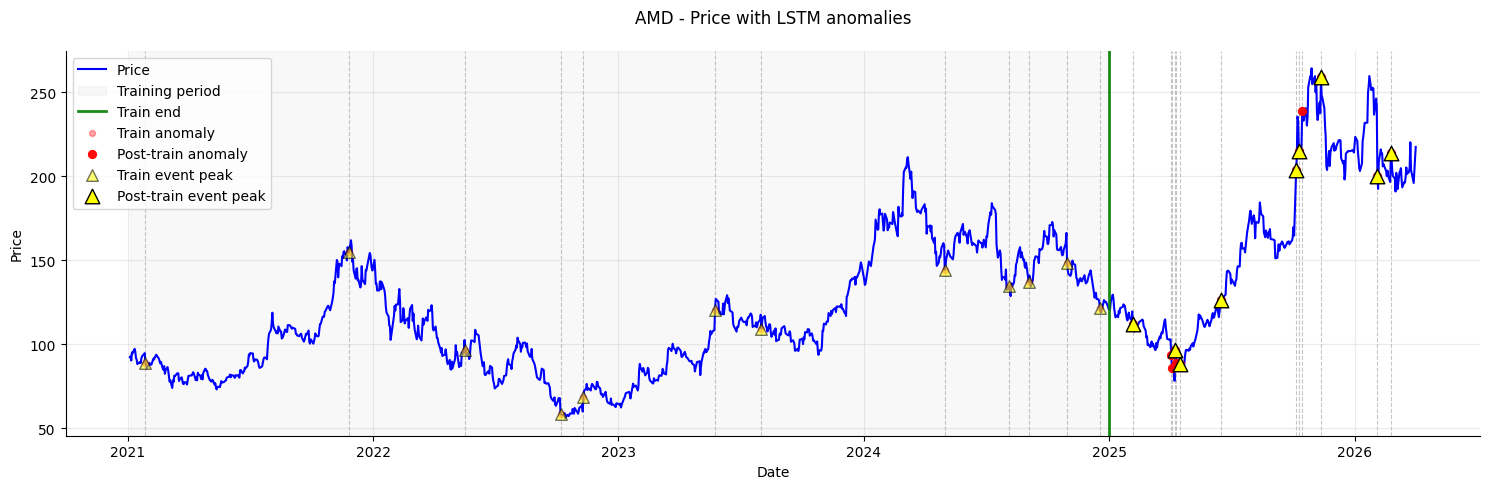

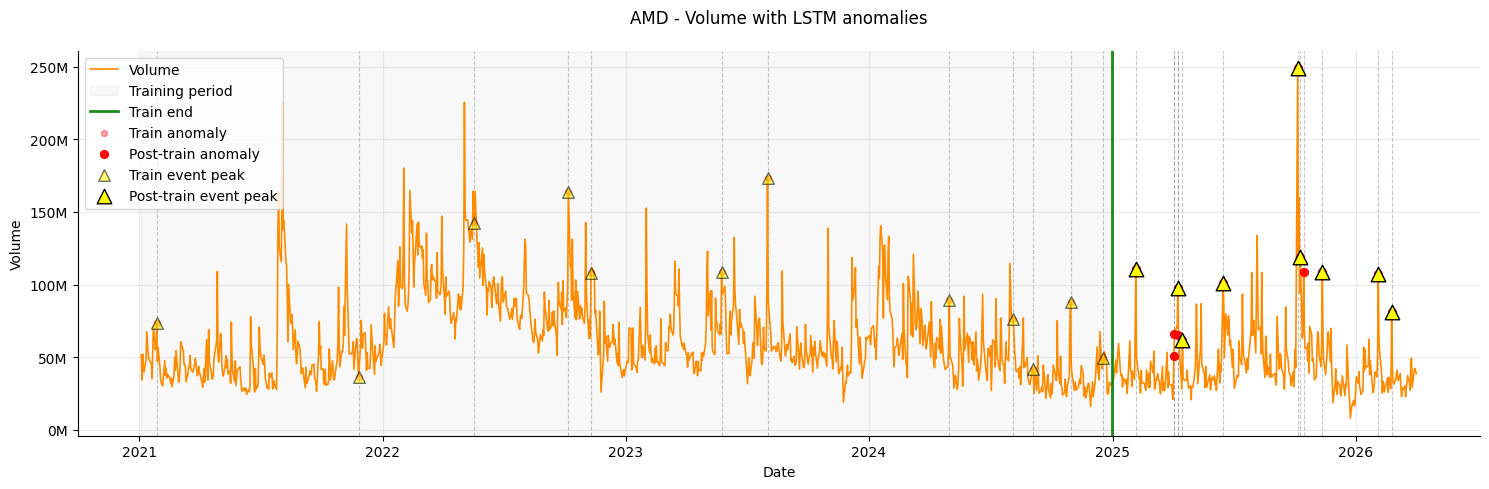

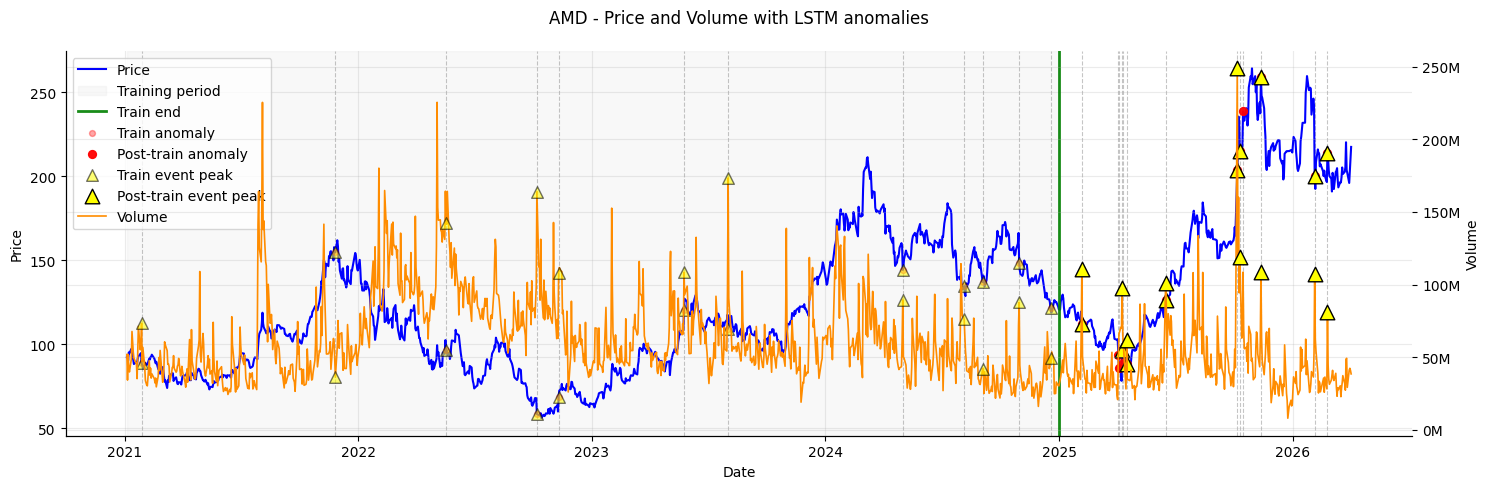

================================================================================   HIMS   ================================================================================ 



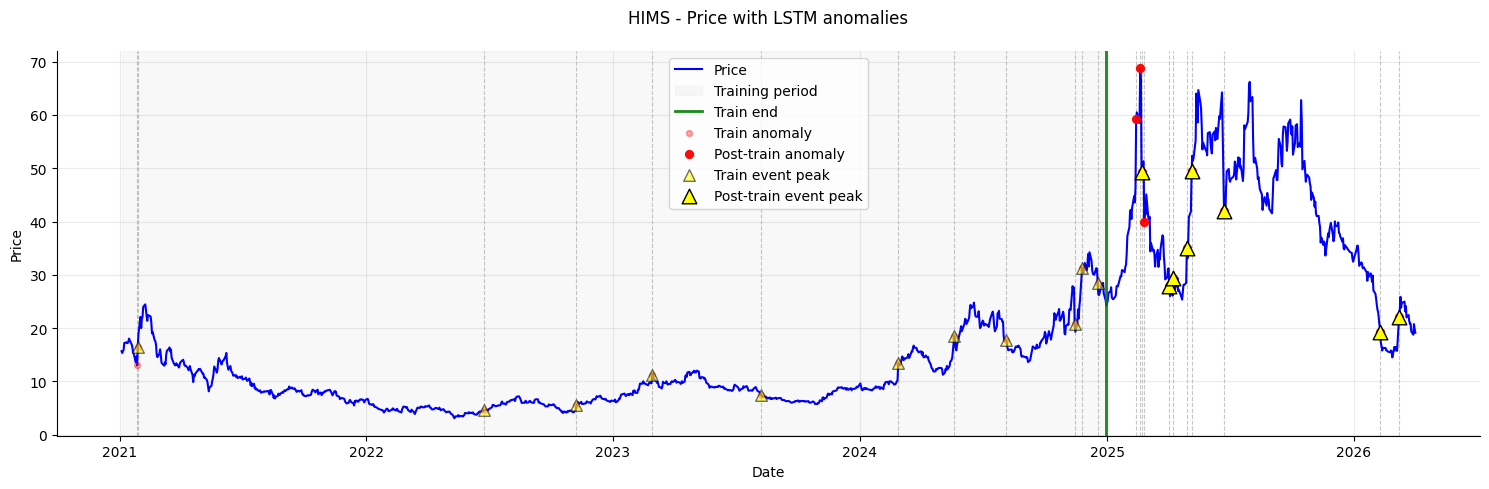

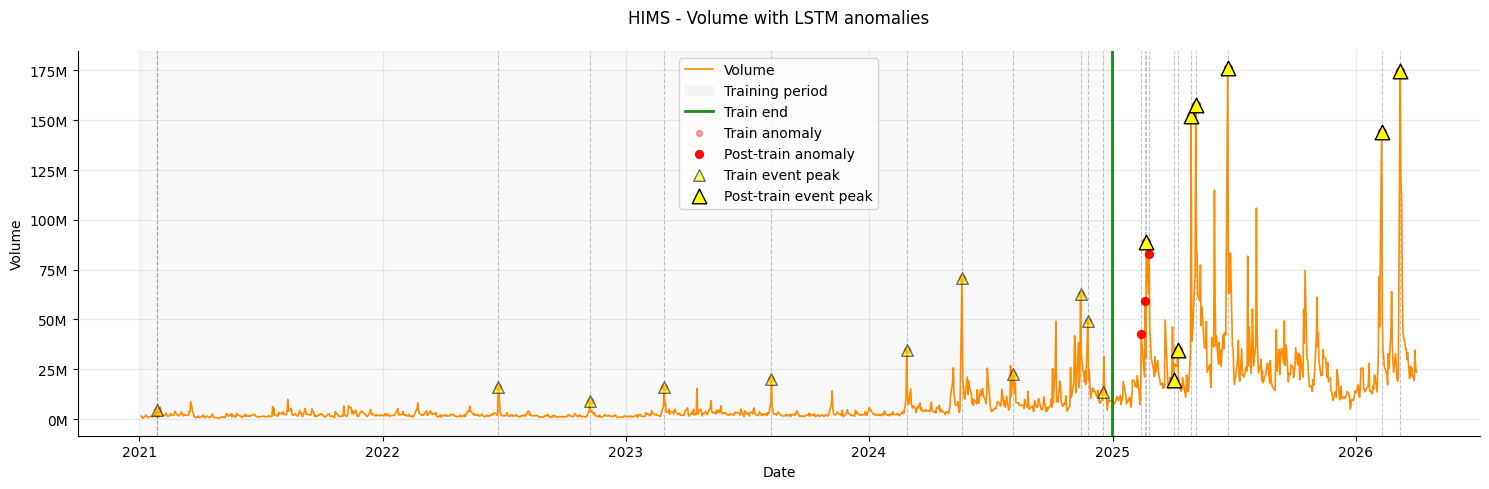

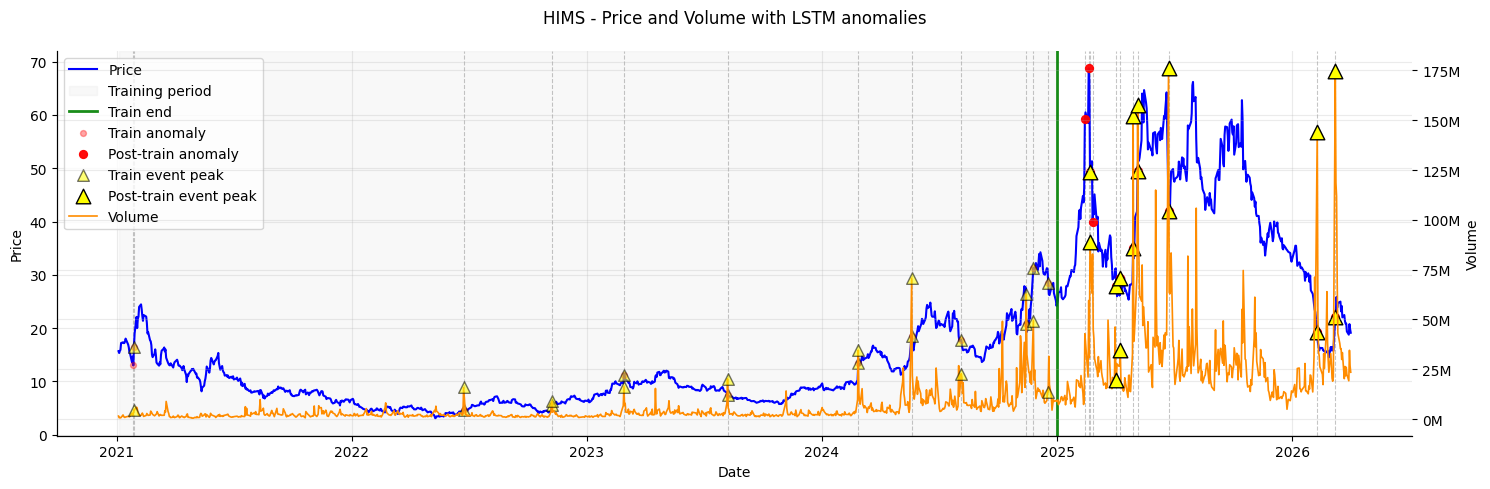

================================================================================   ORCL   ================================================================================ 



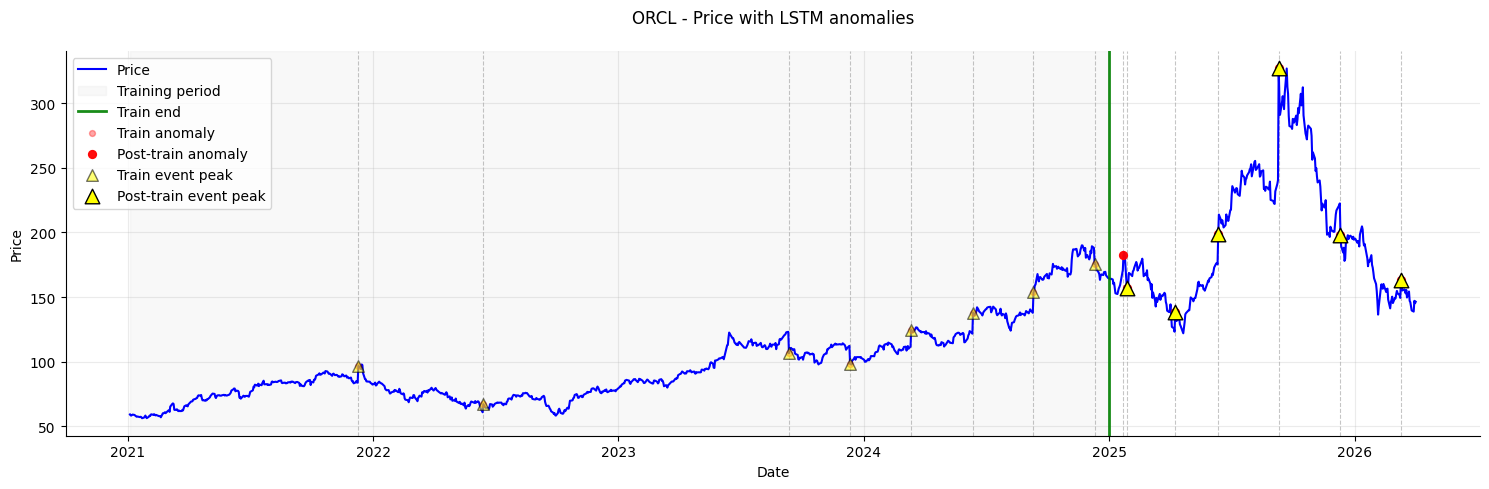

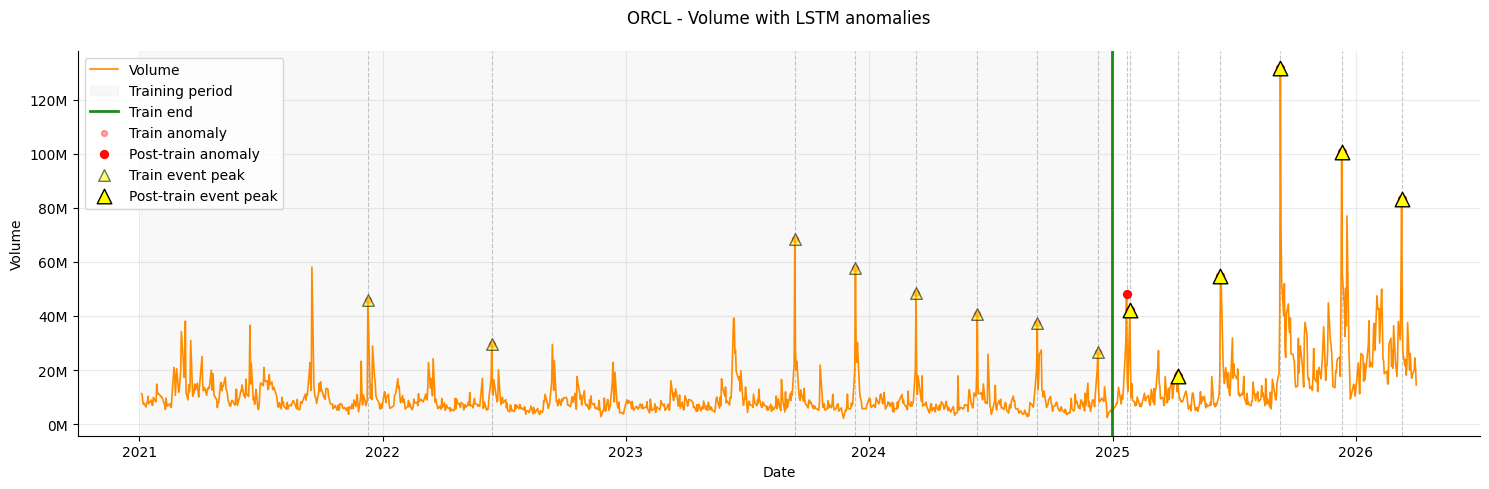

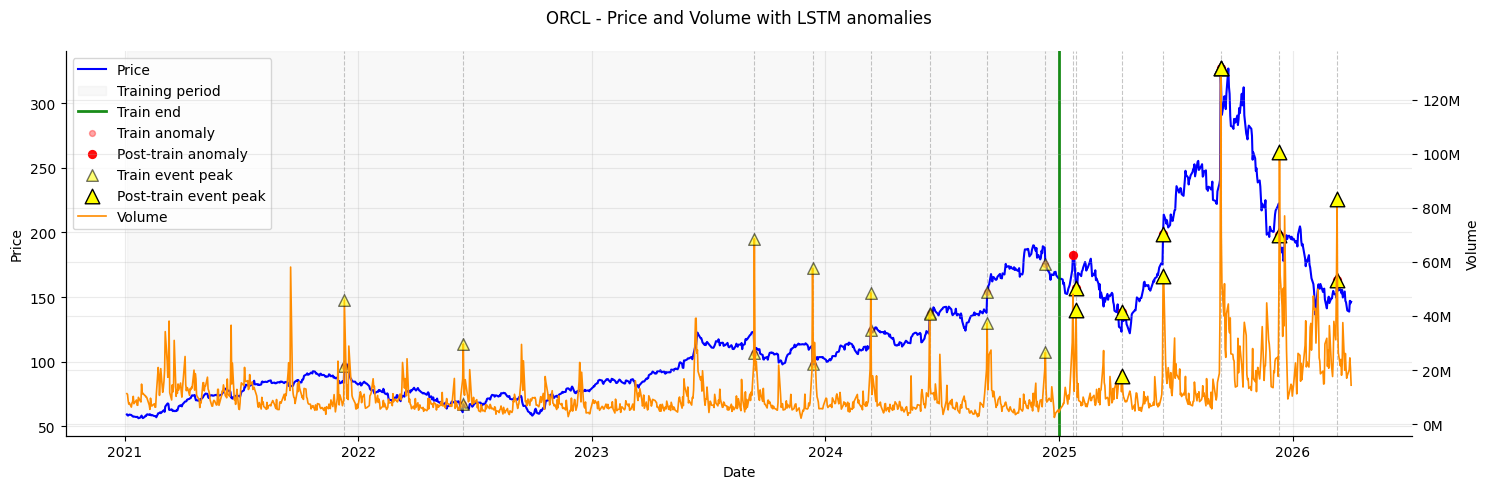

================================================================================   PLUG   ================================================================================ 



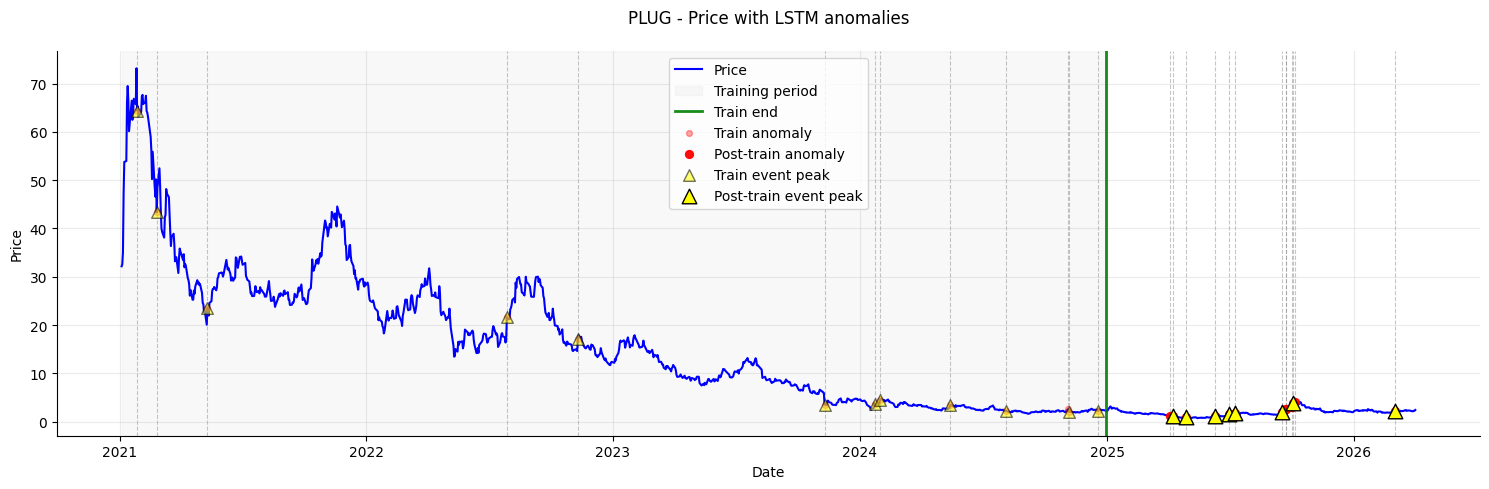

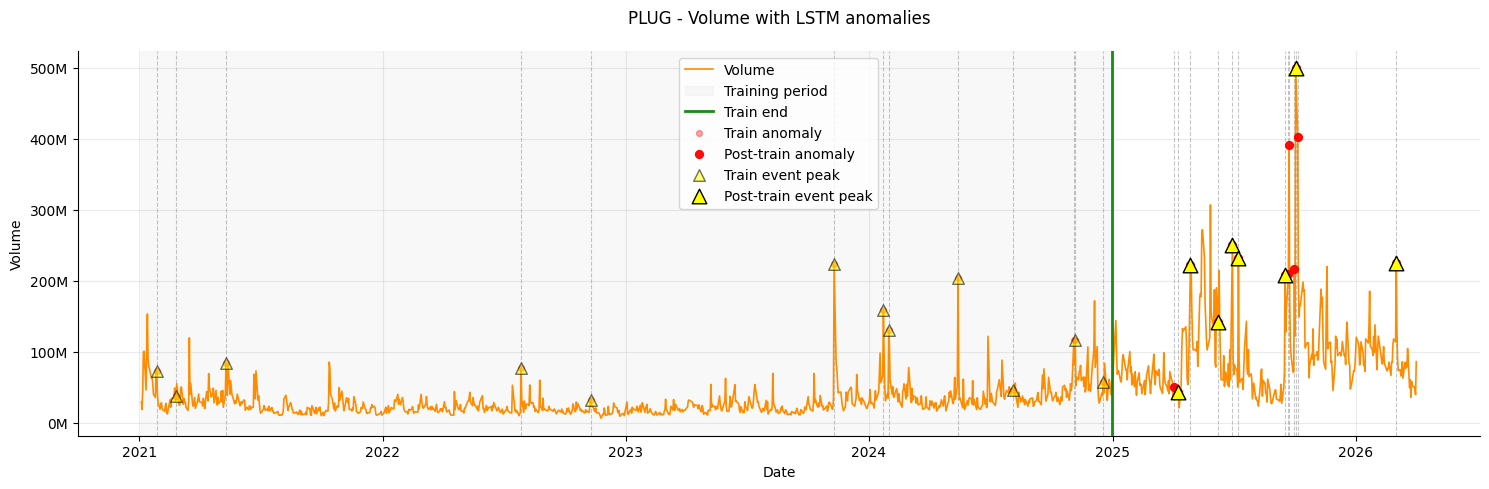

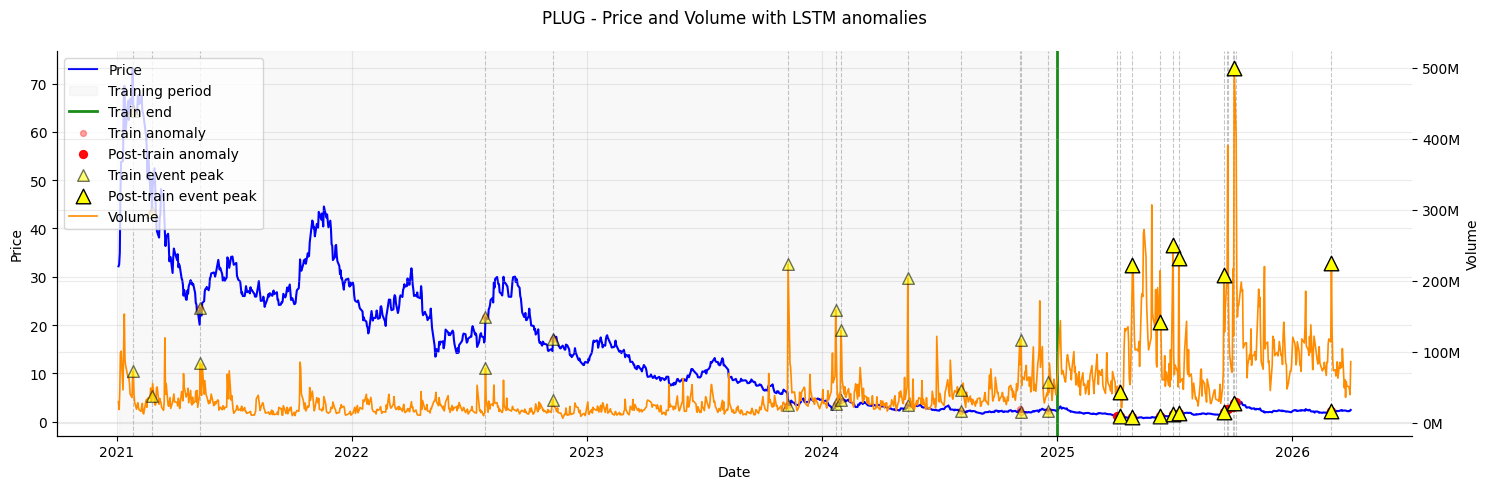

In [98]:
# # plot_anomalies(STOCK_SERIES, results_df)
# plot_anomalies(STOCK_SERIES, results_df, volume_style="line")
for i in range(len(STOCK_SERIES)):
    print("="*80 + "   " + STOCK_SERIES[i] + "   " + "="*80, "\n" )
    plot_price_volume_and_anomalies(STOCK_SERIES[i], results_df, volume_style="line")
# plot_price_volume_and_anomalies(STOCK_SERIES, results_df, volume_style="bars")


================================================================================   AMD   ================================================================================ 



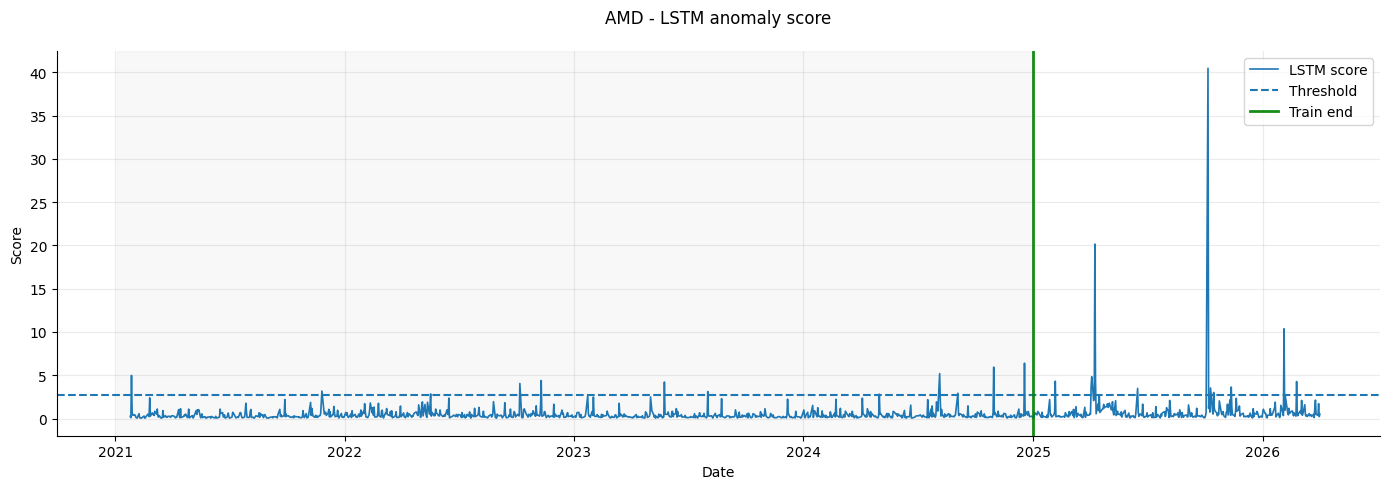

================================================================================   HIMS   ================================================================================ 



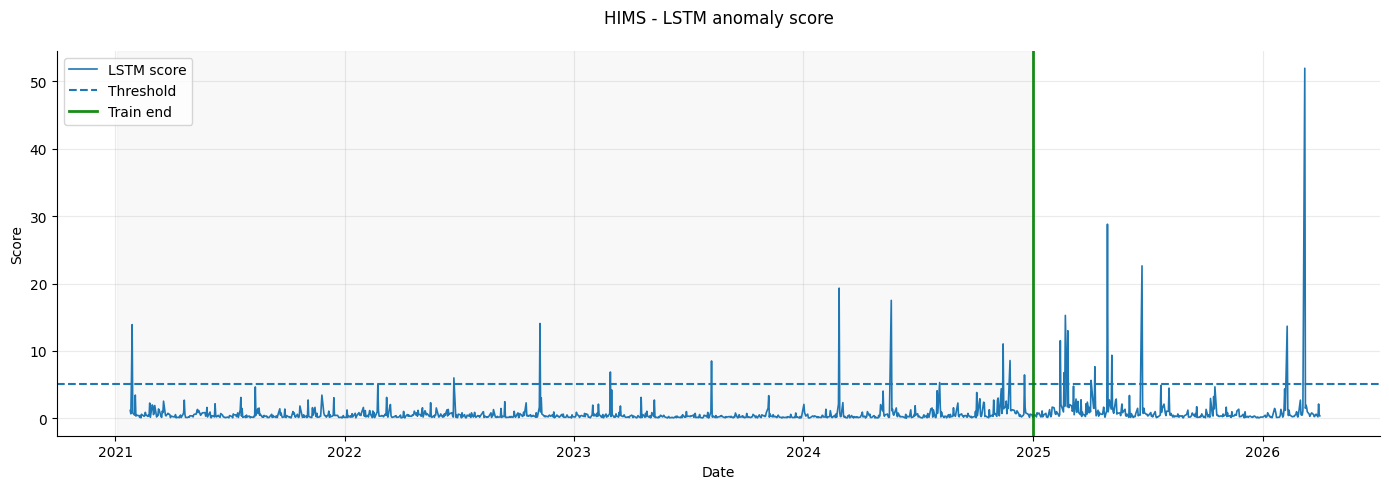

================================================================================   ORCL   ================================================================================ 



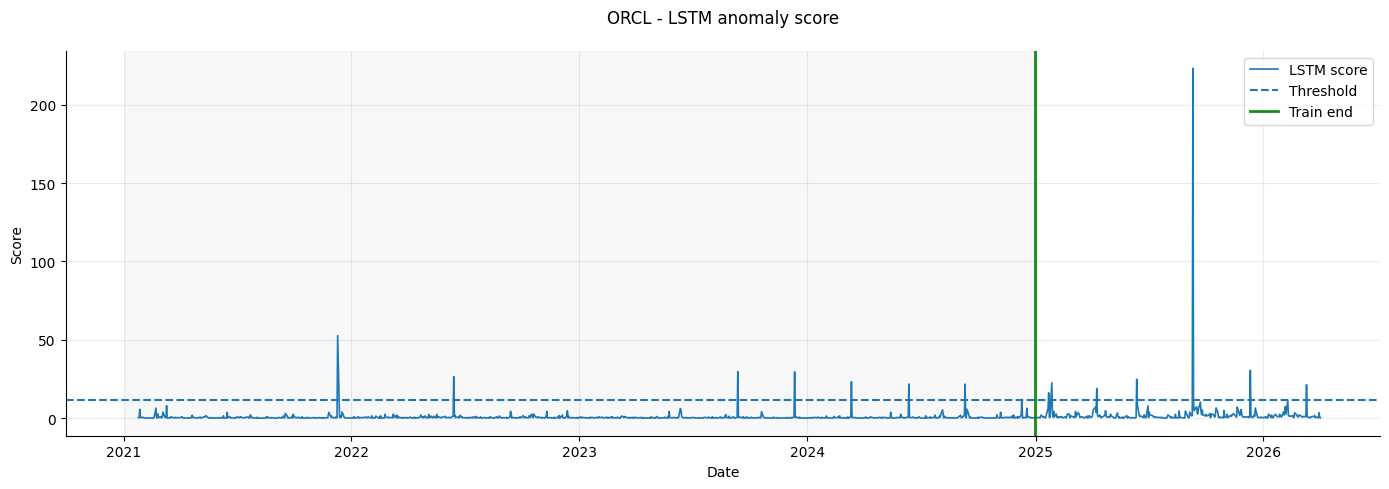

================================================================================   PLUG   ================================================================================ 



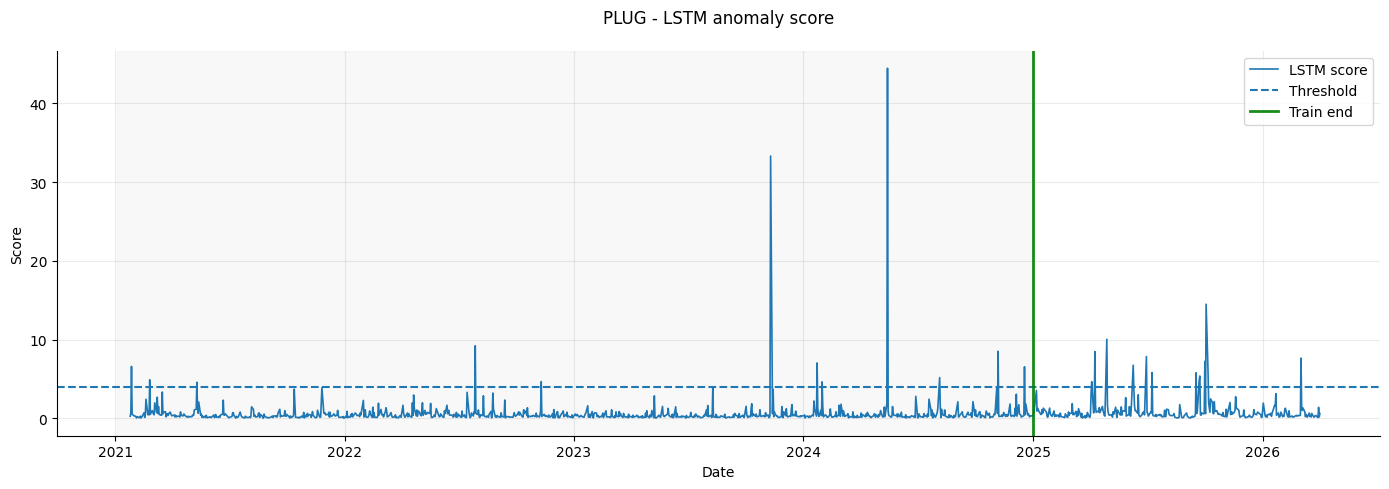

In [100]:
for i in range(len(STOCK_SERIES)):
    print("="*80 + "   " + STOCK_SERIES[i] + "   " + "="*80, "\n" )
    plot_score(STOCK_SERIES[i], results_df)



================================================================================   AMD   ================================================================================ 



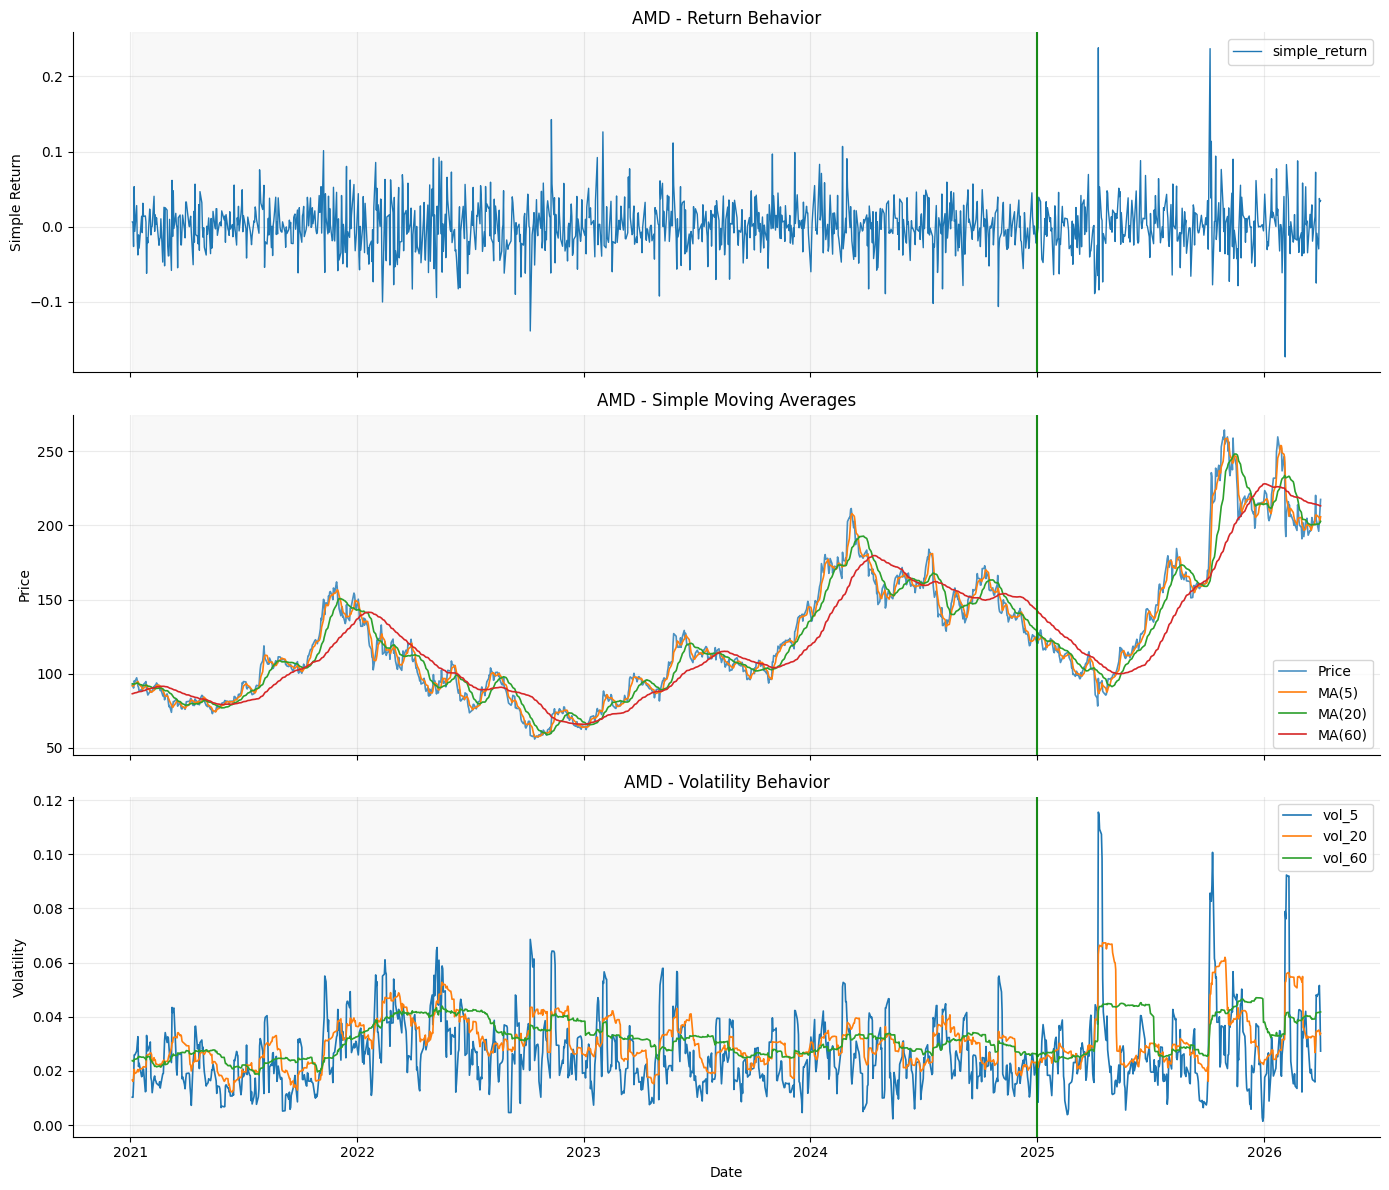

================================================================================   HIMS   ================================================================================ 



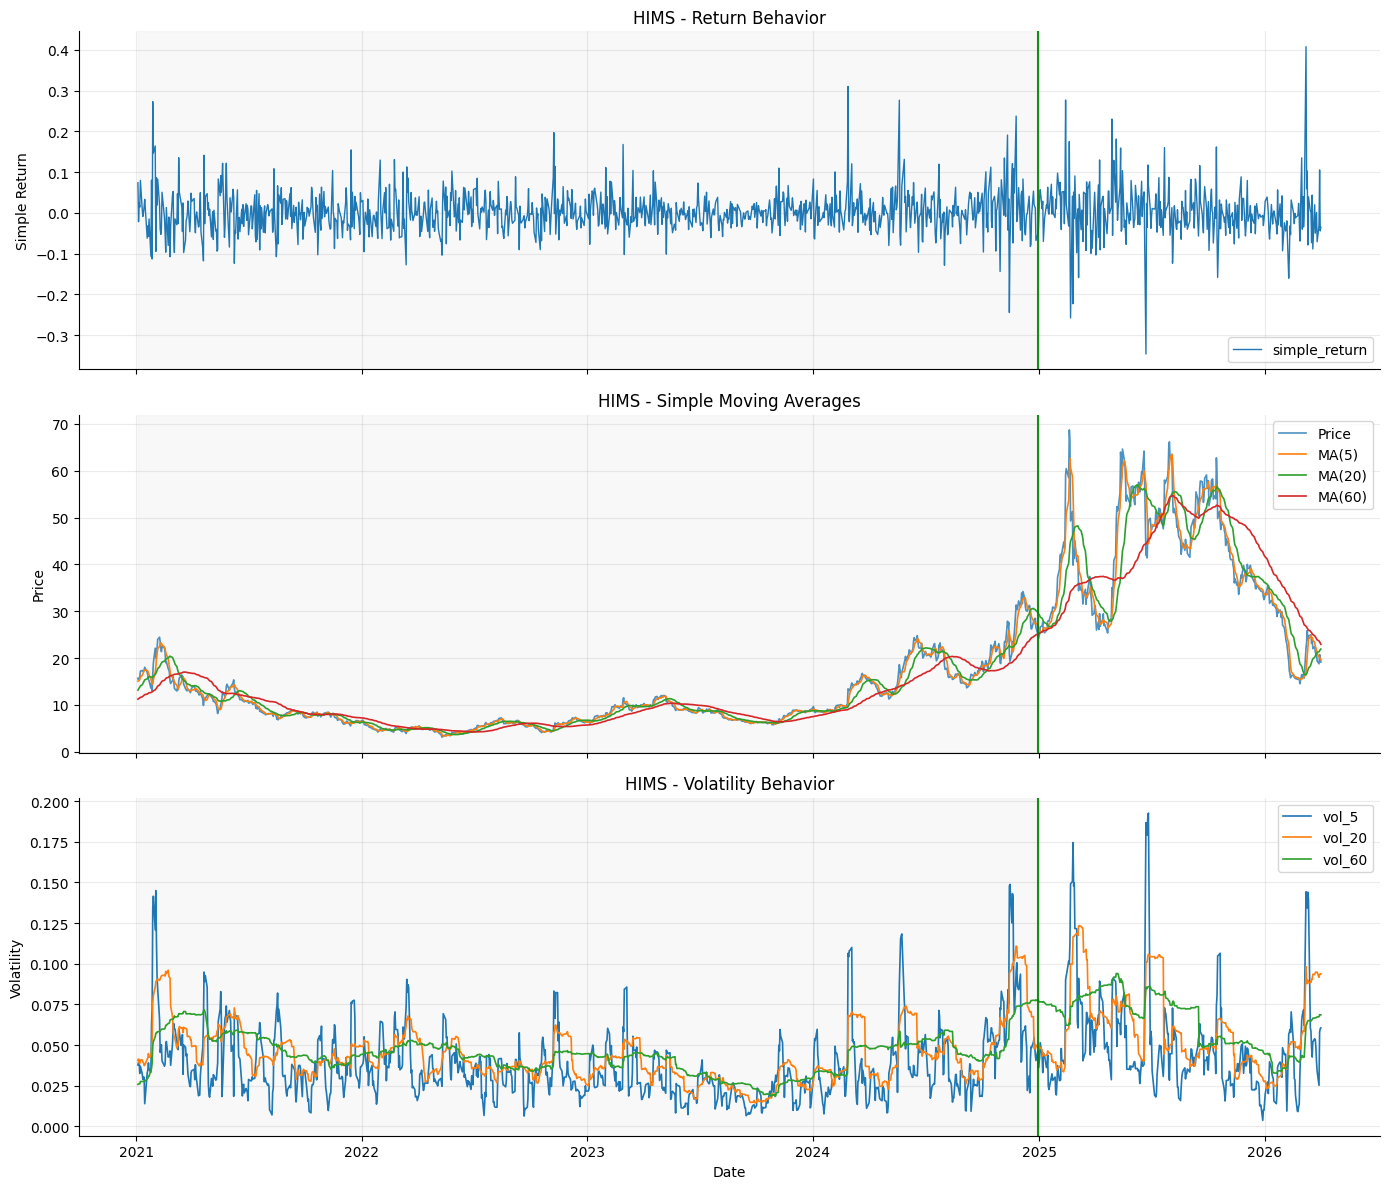

================================================================================   ORCL   ================================================================================ 



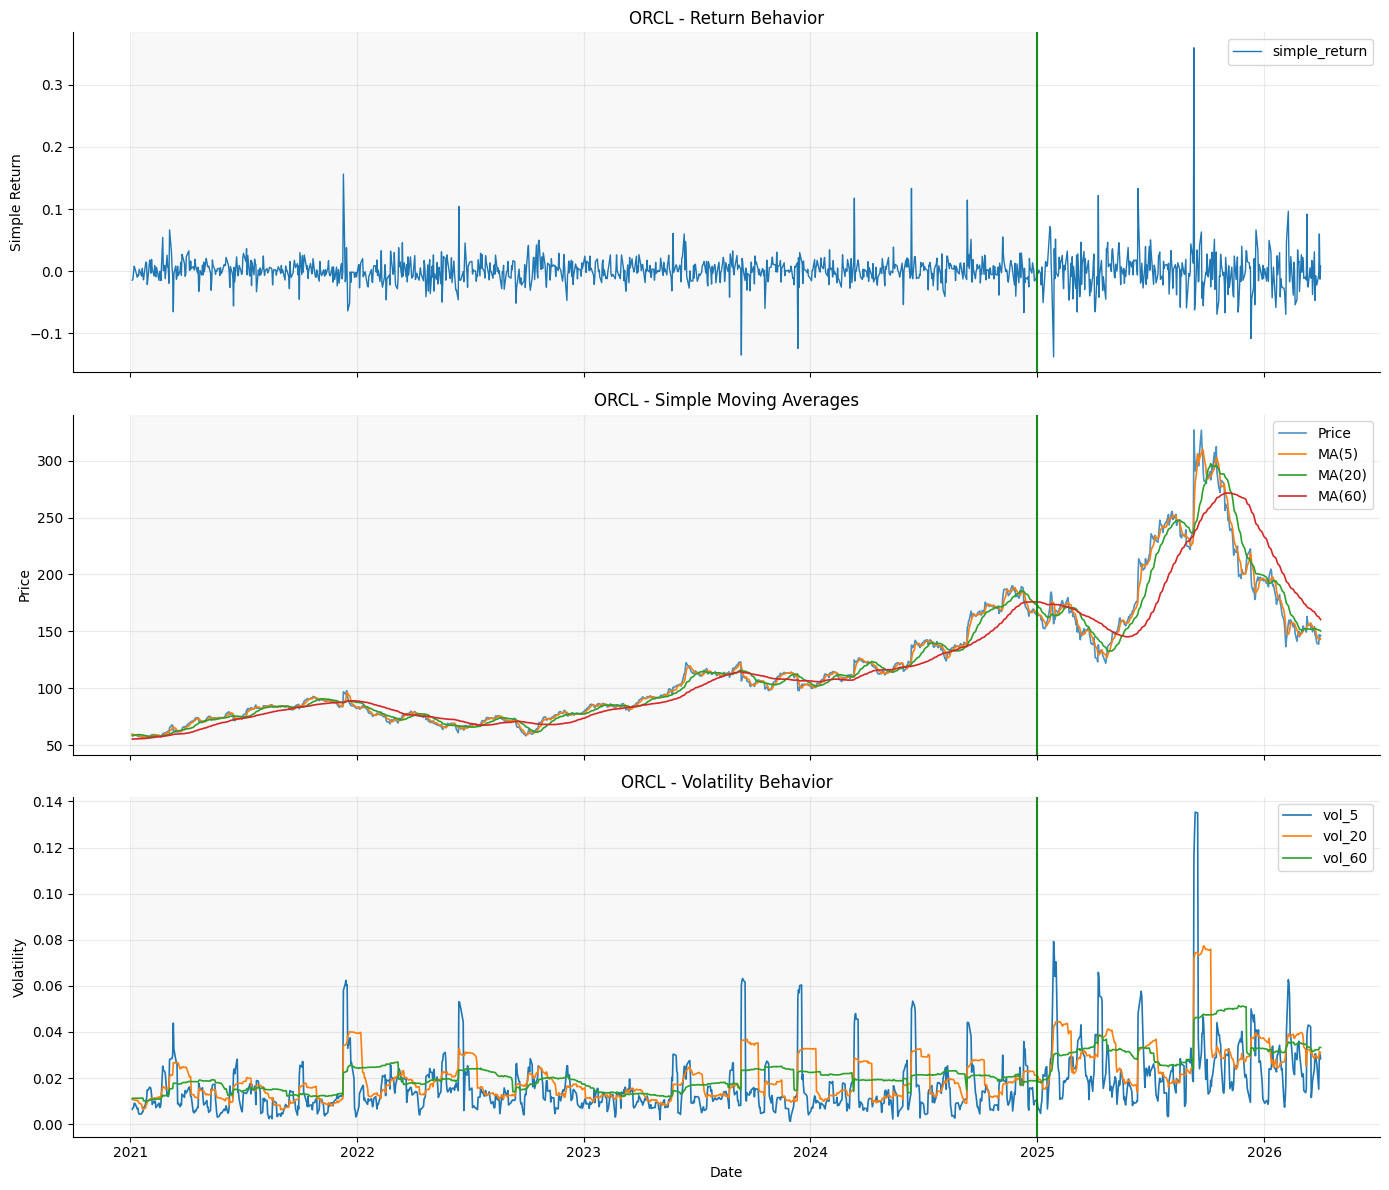

================================================================================   PLUG   ================================================================================ 



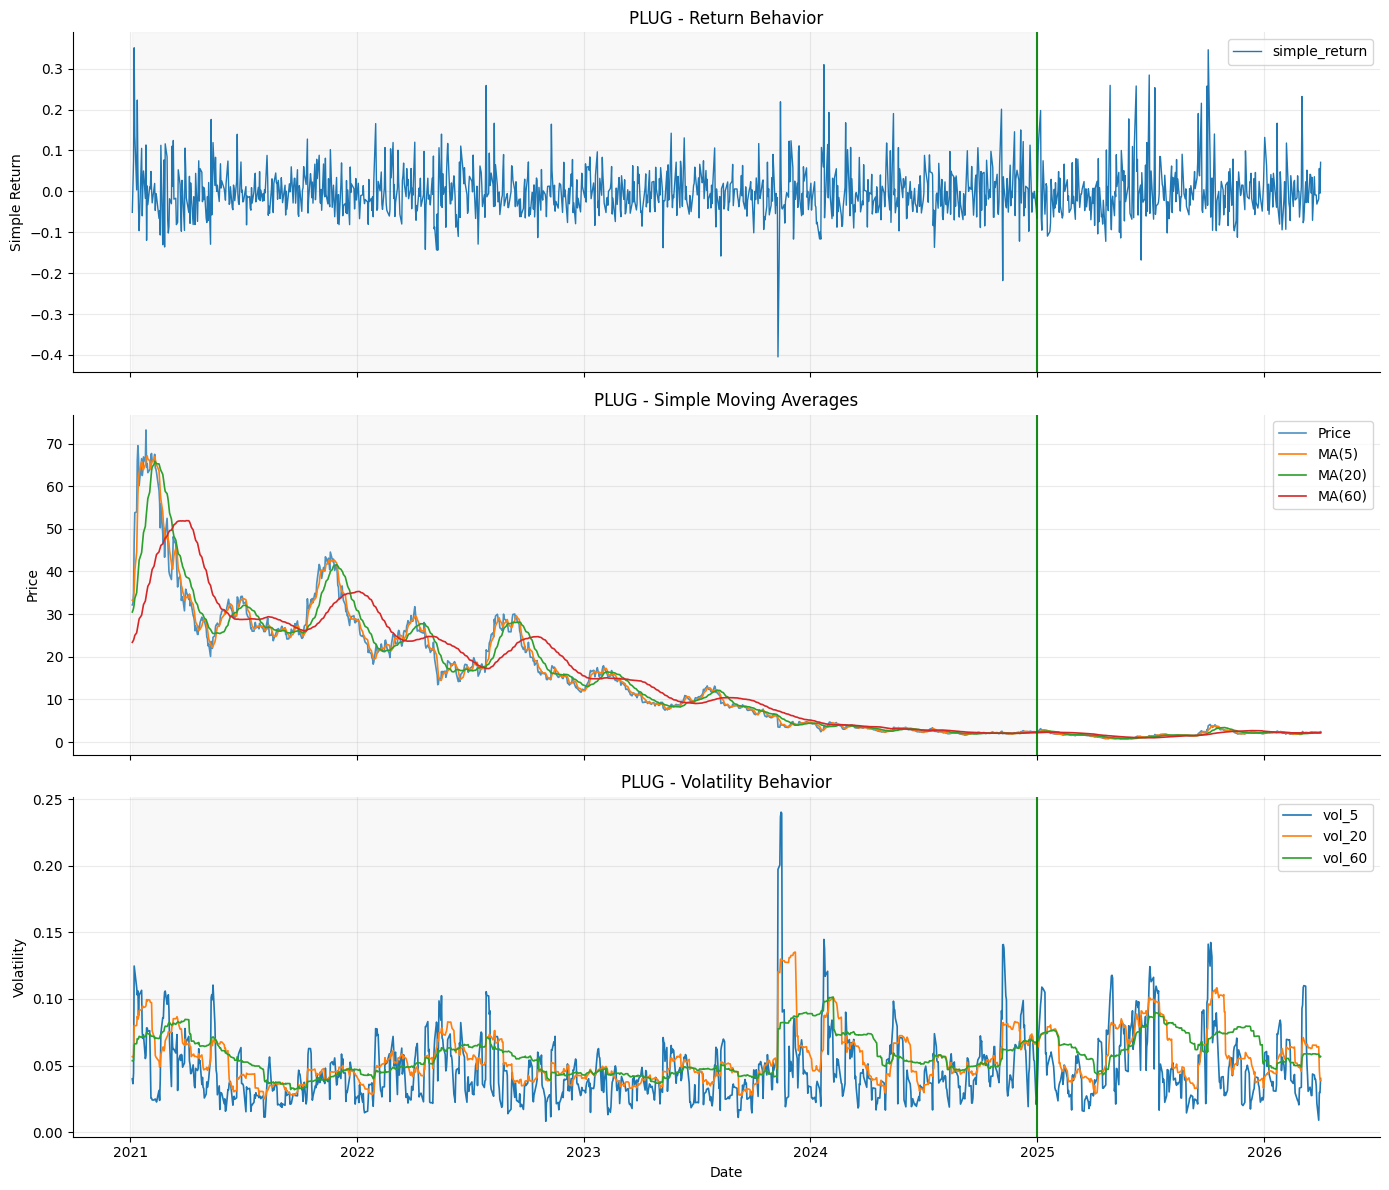

In [101]:
for i in range(len(STOCK_SERIES)):
    print("="*80 + "   " + STOCK_SERIES[i] + "   " + "="*80, "\n" )
    plot_selected_features(STOCK_SERIES[i], subset_df)



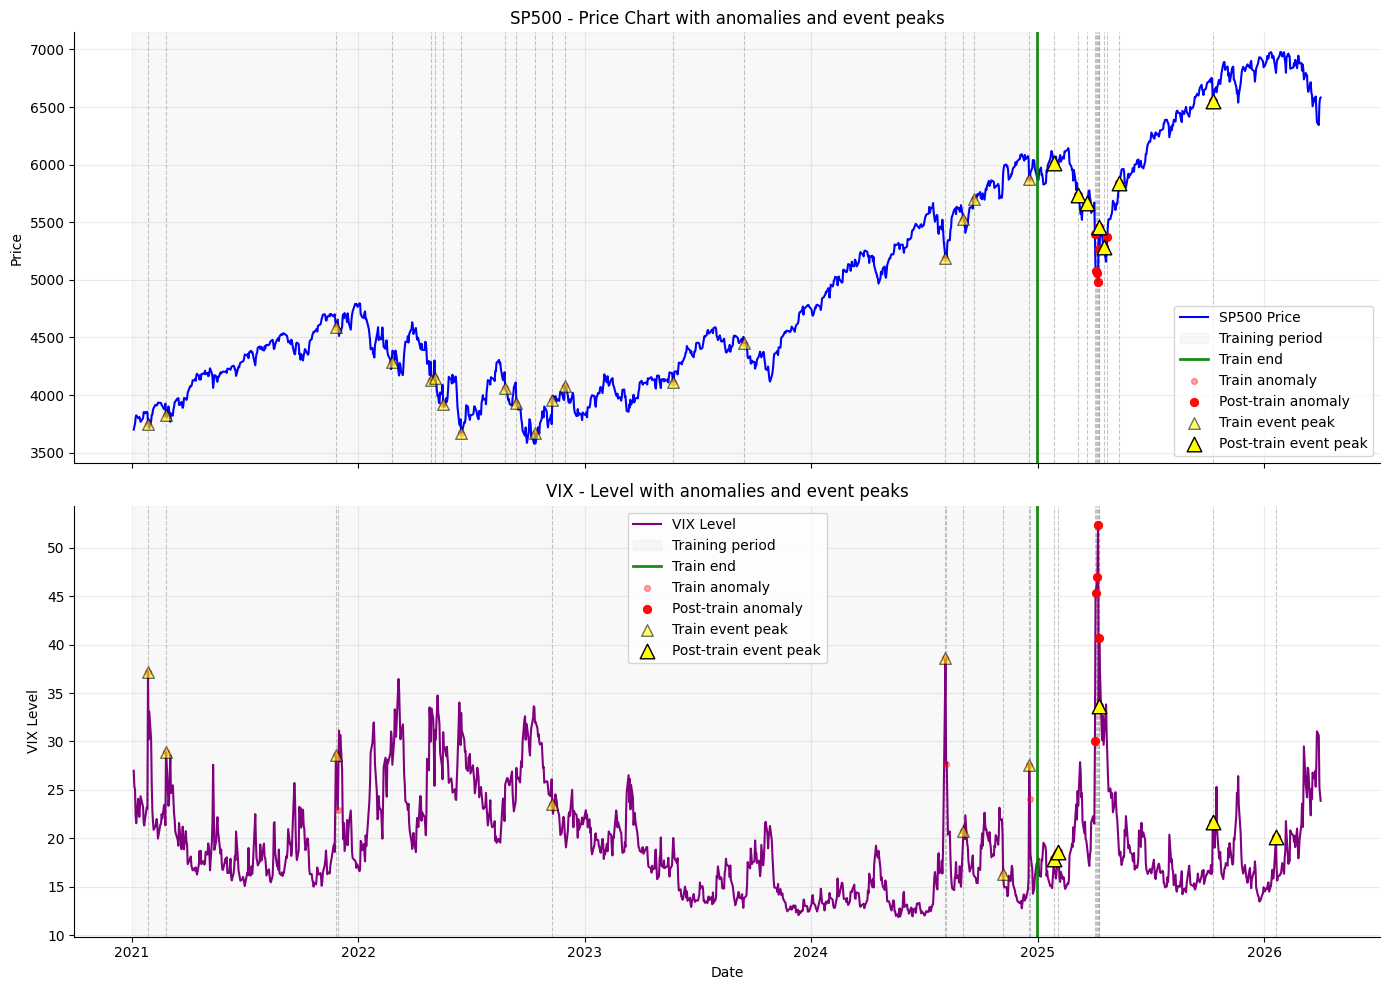

In [102]:
plot_market_context_with_anomalies(results_df)


## 14. Inspect anomaly tables for the selected stock

In [107]:
display(train_anomaly_table.sort_values("lstm_score", ascending=False).head(20))


,Date,SeriesName,Price,lstm_score,lstm_threshold,lstm_is_event_peak_all
996,2024-12-18,AMD,121.410004,6.042797,2.592853,True
901,2024-08-05,AMD,134.820007,5.228046,2.592853,True
962,2024-10-30,AMD,148.600006,4.626090,2.592853,True
444,2022-10-07,AMD,58.439999,4.311820,2.592853,True
16,2021-01-27,AMD,88.839996,4.094281,2.592853,True
602,2023-05-25,AMD,120.349998,4.064959,2.592853,True
227,2021-11-26,AMD,154.809998,3.486994,2.592853,True
586,2023-05-03,AMD,81.620003,3.082385,2.592853,True
468,2022-11-10,AMD,68.470001,2.902451,2.592853,True
836,2024-05-01,AMD,144.270004,2.753060,2.592853,True


In [104]:
display(post_anomaly_table.sort_values("lstm_score", ascending=False).head(20))


,Date,SeriesName,Price,lstm_score,lstm_threshold,lstm_is_event_peak
1194,2025-10-06,AMD,203.710007,39.336023,2.592853,True
1071,2025-04-09,AMD,96.839996,19.233537,2.592853,True
1277,2026-02-04,AMD,200.190002,11.364197,2.592853,True
1068,2025-04-04,AMD,85.760002,5.155316,2.592853,False
1072,2025-04-10,AMD,88.699997,4.352613,2.592853,False
1027,2025-02-05,AMD,112.010002,4.085617,2.592853,True
1290,2026-02-24,AMD,213.839996,3.996233,2.592853,True
1067,2025-04-03,AMD,93.800003,3.993668,2.592853,False
1201,2025-10-15,AMD,238.600006,3.259953,2.592853,True
1198,2025-10-10,AMD,214.899994,3.251400,2.592853,False


## 15. Compare anomaly counts across the four series only

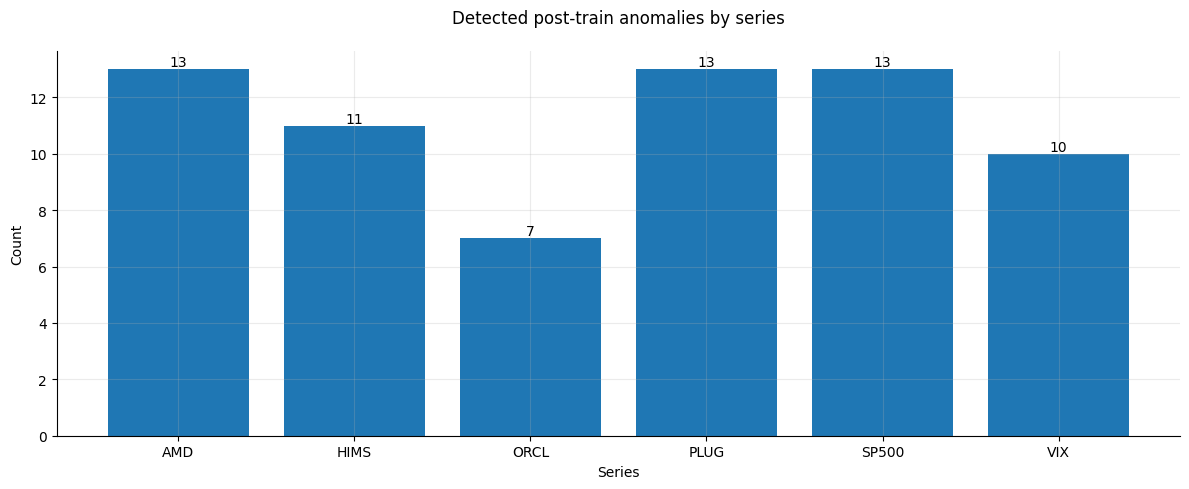

In [105]:
summary_plot = summary_df.copy()

plt.figure(figsize=(12, 5))
bars = plt.bar(summary_plot["SeriesName"], summary_plot["n_anomalies_detected"])
plt.title("Detected post-train anomalies by series", pad=20)
plt.xlabel("Series")
plt.ylabel("Count")

for bar, value in zip(bars, summary_plot["n_anomalies_detected"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(value)}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()


The notebook is intentionally constrained to one stock plus three benchmark indices.

That makes the deep-learning analysis:
- cheaper to run,
- easier to interpret,
- and easier to explain in the project report.

Interpretation:
- `lstm_is_anomaly_all` shows how the model scores the full sample,
- `lstm_is_anomaly` is the post-train detected anomaly flag,
- event peaks compress nearby anomaly dates into one representative event.

We can repeat the notebook for another stock by changing `STOCK_SERIES` at the top and rerunning the notebook.
